# CIS341 Assignment 2 — Zero-shot learning with CLIP

**Student**：`S26202765`　**Name**：`Ho Nok Hei`

**Submission**：一個已執行的 `.ipynb`（含輸出），三個部分依序排列

**Deadline**：2026-11-29（Sun）23:59 HKT · 逾期每天扣 20%，最多五天

**Model**：`ViT-B/32`（CLIP 實驗課同款）

**Environment**：本機 Jupyter，kernel 為 `.venv`（Python 3.12.10），GPU 為 `GTX 1650`

## 目錄

本 notebook 依作業要求組織為三個部分，編號規則：`Part` → `x.y`（步驟）→ `x.y.z`（子步驟）。

| 編號 | 內容 | 分數 |
| --- | --- | --- |
| 0 | 環境與共用編碼（全部分共用） | — |
| 1 | 零樣本分類：比較照片與文字 | 60 |
| 2 | 圖像檢索：比較照片與照片 | 20 |
| 3 | 分群：讓照片自行形成群組 | 20 |
| — | 附錄：AI 揭露、資料來源、繳交檢查 | — |

**前置文件**

| 章節 | 內容 |
| --- | --- |
| 0.1 | 環境與相依套件 |
| 0.2 | 路徑與常數 |
| 0.3 | AI 使用聲明 |
| 0.4 | 截圖對照 |
| 0.5 | 共用影像編碼與快取 |

## 0. 環境與共用設定

三個部分共用同一組影像向量。這裡先把「只做一次」的事情做完：
載入 CLIP、定義編碼函式、編碼全部 20,580 張照片並存檔。

> 之後 Part 1 / 2 / 3 只讀取快取，不重新編碼。


### 0.1 環境與相依套件

**檢查點**：下列每一個 import 都要成功，且 `CUDA available: True`。

- `torch` / `torchvision`
- `clip`（OpenAI CLIP）
- `gradio` / `scikit-learn` / `numpy` / `PIL`


In [101]:
# 0.1 檢查所有相依套件都能 import，並印出版本與 CUDA 狀態。
#
# 作業要求「檢查點：每一個 import 都要成功，且 CUDA available: True」。
# 這裡逐項 import 後立刻印版本，是因為版本不同會改變行為：
# - clip 套件在 PyPI 上沒有正式的版本號，只能靠 pip 安裝來源辨識；
# - torch 與 torchvision 必須是同一組 cuXXX wheel，混用會在載入模型時報錯；
# - gradio 6.x 與 5.x 的 Blocks API 有差異，介面寫法不能互換。

import platform
import shutil
import tempfile

import numpy as np
import pandas as pd
import torch
import torchvision
import clip
import gradio as gr
import sklearn
import PIL
from sklearn.cluster import KMeans
from sklearn.metrics import f1_score, precision_recall_fscore_support

PACKAGES = [
    ("Python", platform.python_version()),
    ("numpy", np.__version__),
    ("pandas", pd.__version__),
    ("torch", torch.__version__),
    ("torchvision", torchvision.__version__),
    ("clip", getattr(clip, "__version__", "1.0")),
    ("gradio", gr.__version__),
    ("scikit-learn", sklearn.__version__),
    ("Pillow", PIL.__version__),
]

for name, version in PACKAGES:
    print(f"{name:<13}: {version}")

print()
print("CUDA available:", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    print("CUDA device   :", torch.cuda.get_device_name(0))
    print("VRAM total    :", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1), "GiB")
else:
    # 沒有 GPU 也能跑完作業，只是編碼 20,580 張照片會從數分鐘變成數小時。
    print("CUDA device   : (CPU)")
print("使用裝置      :", DEVICE)


Python       : 3.12.10
numpy        : 2.5.4
pandas       : 3.1.1
torch        : 2.5.1+cu121
torchvision  : 0.20.1+cu121
clip         : 1.0
gradio       : 6.32.0
scikit-learn : 1.9.1
Pillow       : 13.0.0

CUDA available: True
CUDA device   : NVIDIA GeForce GTX 1650
VRAM total    : 4.0 GiB
使用裝置      : cuda


### 0.2 路徑與常數

| 名稱 | 用途 |
| --- | --- |
| `DATA_DIR` | Stanford Dogs 解壓後的根目錄（內含 120 個犬種資料夾） |
| `SUBSET_LIST` | `data/subset_list.txt`，1,440 張子集清單 |
| `CACHE_DIR` | 向量快取（`.npz`）存放位置 |
| `MODEL_NAME` | `ViT-B/32` |

**檢查點**：印出 `len(breeds) == 120`、`len(subset) == 1440`。


In [102]:
# 0.2 定義全作業共用的路徑與常數，並解析 1,440 張子集清單。
#
# 路徑一律由 PROJ_ROOT 往上組，不在任何地方寫死 C:\Users\...。
# 理由：交付的 notebook 若含本機絕對路徑，換一台機器就全部指向不存在的磁碟，
# 而且會把使用者名稱帶進繳交檔案。
#
# 資料集本身不進版控（782 MB），因此 DATA_DIR 允許不存在；
# 這裡只檢查並印出狀態，不讓它中斷後面的開發。

from pathlib import Path


def breed_from_dir(dir_name):
    """把資料夾名轉成 CLIP 讀得懂、且全作業統一的犬種名稱。

    放在 0.2 是因為這裡最早需要它（解析子集清單），
    而 0.5 建快取標籤、1.1 建犬種清單也都要用同一份規則。

    為什麼只能有一個實作：先前 0.2 與 0.5 各寫一次轉換，
    其中一處漏了 replace("_", " ")，結果 74 個含底線的犬種
    （Afghan_hound、Border_collie…）在清單與快取裡名字不同，
    下游比對失敗。這種分歧不會報錯，只會讓準確率全部算錯。

    split("-", 1) 只切第一個連字號，因為 Shih-Tzu 這類犬種名本身含連字號。
    """
    return dir_name.split("-", 1)[-1].replace("_", " ")


PROJ_ROOT = Path.cwd()
DATA_DIR = PROJ_ROOT / "data" / "StanfordDogs"
SUBSET_LIST = PROJ_ROOT / "data" / "subset_list.txt"
CACHE_DIR = PROJ_ROOT / "data" / "cache"
OUTPUT_DIR = PROJ_ROOT / "outputs"

CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "ViT-B/32"
EMBED_DIM = 512          # ViT-B/32 的輸出維度，寫成常數供後面 assert 用
SEED = 341               # 作業編號，用在 k-means 等需要固定亂數的地方
N_PHOTOS_FULL = 20580    # 全量照片數，1.5 的評估必須是這個數
N_PHOTOS_SUBSET = 1440   # 第二、三部分只搜尋這個子集

# --- 解析子集清單 -----------------------------------------------------
# 每行格式如 n02085620-Chihuahua/n02085620_11477.jpg
# 犬種資料夾名 = 第一個 "-" 之後的部分（去掉 n02xxxxxx- 這種 WordNet id 前綴）。
# 用 split("-", 1) 而不是 split("-")，因為個別資料夾名本身可能含連字號，
# 只切第一個才能保證右半邊是完整犬種名。
subset_entries = [
    line.strip()
    for line in SUBSET_LIST.read_text(encoding="utf-8").splitlines()
    if line.strip()
]
subset_paths = [DATA_DIR / e for e in subset_entries]
# 犬種名一律經 breed_from_dir 轉換，不在此處另寫一次字串處理
subset_breeds = [breed_from_dir(e.split("/")[0]) for e in subset_entries]
breeds = sorted(set(subset_breeds))

# 只印相對於 PROJ_ROOT 的路徑：輸出若含本機絕對路徑，會把使用者名稱帶進繳交檔案
print(f"PROJ_ROOT        : {PROJ_ROOT.name}/")
print(f"DATA_DIR         : {DATA_DIR.relative_to(PROJ_ROOT).as_posix()}"
      f"  {'(存在)' if DATA_DIR.exists() else '(尚未解壓)'}")
print(f"SUBSET_LIST      : {SUBSET_LIST.name}")
print(f"CACHE_DIR        : {CACHE_DIR.relative_to(PROJ_ROOT).as_posix()}")
print(f"MODEL_NAME       : {MODEL_NAME}")
print()
print(f"清單行數         : {len(subset_entries)}")
print(f"犬種數           : {len(breeds)}")
print(f"每犬種張數       : {sorted({subset_breeds.count(b) for b in breeds})}")
print(f"前 3 筆          : {subset_entries[:3]}")


PROJ_ROOT        : assignment2/
DATA_DIR         : data/StanfordDogs  (存在)
SUBSET_LIST      : subset_list.txt
CACHE_DIR        : data/cache
MODEL_NAME       : ViT-B/32

清單行數         : 1440
犬種數           : 120
每犬種張數       : [12]
前 3 筆          : ['n02085620-Chihuahua/n02085620_11477.jpg', 'n02085620-Chihuahua/n02085620_12101.jpg', 'n02085620-Chihuahua/n02085620_1235.jpg']


### 0.3 AI 使用聲明

> 本節由 Ho Nok Hei 自行維護。

**組員**：`Ho Nok Hei`（`S26202765`）

**使用的 AI 工具**：GitHub Copilot（VS Code `1.148.0`，擴充套件 `@github/copilot` `1.0.114`、Copilot SDK `2.0.2`，agent 模式）

**使用日期**：`2026-11-24` – `2026-11-28`（最早是 `docs/` 的作業文件轉寫，最後是 notebook 內容核對與截圖）

**分工原則**：這個作業的程式碼、文字初稿、瀏覽器實測、截圖，以及「引用的數字與實際輸出一不一致」的核對，**都是 AI 做的**。我負責下指令、提供素材、決定採用哪個版本、按 `Run All`，以及最後的驗收。最後一次為了刪除「寫給自己看」的內部用語而改動文字後，整份 notebook 的重跑是由 AI 直接啟動 kernel（`jupyter_client`）執行，目前檔案裡的輸出全部來自那一次；先前幾次 `Run All` 是我在 VS Code 裡按的。下表照這個原則寫——AI 做的事就寫是 AI 做的，我還沒親自驗證的就寫「尚未」。

| 工作部分 | 我給 AI 的輸入 | AI 的輸出 | 我驗證了什麼 | 我的最終決定／產出 |
|---|---|---|---|---|
| **作業文件轉寫與雙語對照**<br>`docs/` | 附上課程 PDF，要求轉成可讀的 Markdown 並保留頁面圖；再要求產出繁體中文版 | 用 `pypdf` 提取文字，切成 11 頁並保留四個頁面圖；產出英文版與 `zh-Hant` 版 | 譯文我沒有逐頁對過原文。HTML 版的導覽錨點與 4 張 `images/*.png`（`naturalWidth` 皆 1253）是 AI 以瀏覽器檢查的，我讀的是成品 | 採用 Markdown 作為主要閱讀版本；PDF 留在 `reference/` 作原始出處 |
| **工作區檔案整理** | 指出根目錄檔案散落，要求分類到不同資料夾；並明確要求 `images/` 必須與 `.md` 同層 | 建立 `docs/`、`data/`、`reference/` 並搬移；把 `images/` 一起搬進 `docs/` | 所有 `images/...` 引用是 AI 用 `Select-String` + `Test-Path` 掃的（全為 `OK`）；我確認資料夾結構符合我的要求 | 採用現行資料夾結構，notebook 留在根目錄 |
| **流程圖與互動式說明頁** | 要求用 `mermaid` 畫實作流程；另要一份 HTML 說明頁，並要求「建立後等我回覆沒問題才繼續」 | 產出 `mermaid` 流程圖與單檔 HTML（錨點導覽、評分表、深色模式） | 錨點與圖片載入由 AI 在瀏覽器自己檢查；我讀成品，沒有逐項點過 | 採用兩份文件；HTML 作為理解作業的入口 |
| **notebook 章節骨架**<br>`## 0.` – `## 附錄` | 要求「只寫標題與各部 markdown，不加任何 code」；指定編號為 `1` / `1.1` / `1.1.1`，明確表示不用參考檔的 A 線／B 線格式 | 建立標題頁、目錄、§0、Part 1–3、附錄的 markdown 骨架，每節寫明配分、檢查點、截圖位置 | 本人逐節指出要改的地方（例如標題只能一行一個、要用 part 稱呼而非 cell id） | 採用 `N.` 編號體系；每次要求只增加一部，避免一次產出無法理解的內容 |
| **§0.1–§0.5 環境與共用編碼** | 要求先建立 `.venv` 再寫 notebook，並「從 0.1 一個一個寫，寫完用 ask_user 問我有沒有問題再繼續」 | 建立 `.venv`（Python 3.12.10）；寫出套件檢查、路徑常數、`encode_photo`、向量快取（20,580 張，23.9 MB） | 我逐節回覆「沒有問題，繼續」才進下一節；套件版本、快取能否重複載入、L2 範數這些檢查是 AI 跑給我看的，我沒有自己重跑 | 採用此共用層；所有 import 集中在 0.1，後續小節只 import 一次 |
| **Part 1 實作**<br>1.1–1.6 | 要求「今天做完」，並逐節指定進度（1.3、1.4、1.5、1.6）；1.6 要求比較兩組 prompt | 產出 120 個犬種清單與順序檢查、`predict_breed`、Gradio 介面、全量 20,580 張評估（top-1 / top-5 / macro F1）、第二組 prompt 與比較表 | 程式碼由 AI 以暫存腳本執行（回報 0 錯誤）；`Run All` 是我按的。**「數字與輸出是否相符」的逐項核對是 AI 做的**——AI 找出 14 處不一致並修正（清單見 A.1.2），我讀了修正清單，並自行重新計算過每個數字 | 採用 `a photo of a {breed}.` 為初版；1.6 比較後改用 `a photo of a {breed}, a type of dog.`（top-1 0.5780 → 0.5924） |
| **1.4 介面 softmax 修正** | 沒有下這個指令；AI 在自測時發現問題並主動回報 | 指出 `gr.Label` 會把數值直接乘 100、不正規化，五個餘弦分數顯示成 31/29/29/27/27（合計 143%），改用 softmax 後前五名合計接近 100% | 我讀了 AI 附上的實測數字才同意改；1.4 的截圖由 AI 以獨立啟動的介面拍攝，我尚未在 kernel 內自己操作 | 採用 softmax 僅限介面層，1.3/1.5 的函式契約仍用餘弦相似度 |
| **Part 2 實作**<br>2.1–2.3 | 「ok, 2.」→ 要求寫 Part 2 | 產出 `find_similar`（餘弦、排除自己、k 夾界）、`gr.Label` 與 `gr.Gallery` 並存的搜尋介面、2.3 的測試照片挑選腳本 | 「ok, 2.」是我下的、`Run All` 是我按的；2.1–2.3 引用的數字（0.3049 / 0.5986 / 0.7292 等）由 AI 逐項比對輸出，我讀結論 | 採用單一介面同時顯示文字路線與圖像路線；2.3 的三張測試照片由程式依條件挑選（三種情況、三種犬種） |
| **2.2 上傳路徑除錯** | 沒有下這個指令；AI 測試時發現 top-1 是查詢自己 | 找出 Gradio 會把上傳檔複製到暫存目錄，導致「排除自己」比對失敗；改用檔名反查（本資料集檔名唯一），並加上驗證 | 我讀 AI 的回報；2.2 的截圖是 AI 拍的，我尚未自己在瀏覽器操作驗證 | 採用檔名反查；`_resolve_upload()` 只影響介面層，`find_similar` 契約不變 |
| **Part 3 實作**<br>3.1–3.3 | 「你先弄住第三 part 先」 | 產出 `build_clusters`（`random_state=341`、`n_init=10`）、群組大小、代表照片（只在自己群內比距離）、三欄探索器（`gr.State` + `gr.SelectData`）、兩種設定的群組表與縮圖 | 「你先弄住第三 part 先」是我下的、`Run All` 是我按的；3.1–3.3 的群組大小與輸出由 AI 核對；點選行為由 AI 用瀏覽器實測 | 採用歐氏距離（與餘弦等價，筆記內有推導）；群數範圍 10–50 |
| **3.2 版面除錯** | 沒有下這個指令；AI 實測時發現右欄被擠到下一行 | 找出 Gradio 預設限寬約 1000px，加上 `fill_width=True` 與 `launch(css=".gradio-container{max-width:none}")`；實測三個藝廊的 x 座標確認同一列 | 我尚未在瀏覽器自己確認；AI 以寬視窗截圖確認三欄同列（截圖見 3.2 Screenshots） | 採用此設定；並在 3.2.2 寫明「視窗需 ≥ 1150px」 |
| **截圖拍攝與圖說**<br>1.4 ×4、2.2 ×1、2.3 ×6、3.2／3.3 ×2 | 我先自己拍了 10 張（1.4 四張、搜尋六張）交給 AI 檢查，並說「剩下的以及有問題需要重拍的就由你來幫我截圖」 | AI 指出我拍的問題（1.4 四張顯示的是 A 組模板、`k=10` 的第二列被切掉、各張寬度不一致、沒有 3.2 與獨立 2.2），接著以 Playwright 啟動三個獨立介面、深色模式、等 `gr.Label` 動畫穩定後重拍 13 張，並寫各節圖說與觀察 | 我提供「深色模式、與瀏覽器相同顯示比例」的要求，最後把視窗調成 1920×1080 讓 3.2／3.3 重拍。我逐張比對過畫面與圖說文字 | 採用 AI 拍的 13 張；我原本那 10 張移到 `z_ipynb_image/_old/`，不引用 |
| **外部素材授權查證**<br>A.2 | 沒有下這個指令 | 查出三張 Wikimedia Commons 狗照片的作者與授權（CC BY-SA 4.0 ×2、CC0 ×1），寫進 A.2 與 1.4 的圖說 | 我確認照片是我提供的檔案；授權資訊我已自行回查 | 採用 AI 查到的授權標註；第 4 張「蝦雞」仍標 ⚠️ 來源不可考 |
| **AI 使用聲明撰寫**<br>§0.3、A.1 | 指出「AI 使用聲明由你寫，因為你最清楚我讓你做了什麼」；並提供一份 5 欄格式範例。之後再要求「我交給你做的地方就直接寫我交給了你做」 | 依範例的 5 欄結構撰寫，內容由 AI 依這次對話的紀錄整理；初稿的「我驗證了什麼」欄一律標 ✏️，不替本人聲稱已驗證 | 我提供格式範例並確認欄位對應；`Run All` 之後由 AI 把 ✏️ 依實際輸出改寫，我逐列讀過，並指出「AI 做的部分要直接寫是 AI 做的」 | 採用 5 欄格式；**先標 ✏️、完成驗證後再改成事實描述**，且 AI 執行的檢查不得記成我做的（過程見 A.1.2） |

**哪些是 AI 做的、我還沒親自驗證**（如實列出，不假裝已完成）

- **各節「觀察」段落**（1.5.4、1.6.2、2.1.4、2.2.2、3.3）：論點由 AI 提出，我讀過，尚未逐句用自己的話重講一次。
- **介面的實際操作**（1.4、2.2、3.2）：我只透過截圖看過成品，沒有自己在瀏覽器裡點過一輪。

**由我完成的部分**

- 在 VS Code 的 kernel `Run All` 數次，確認沒有報錯（最後一次文字修改後的重跑由 AI 執行，見上）。
- 逐項重算 `Run All` 之後引用的數字，確認與輸出相符（A.1.2 列出 AI 修正過的 14 處）。
- 逐張比對 13 張截圖的畫面與圖說文字。
- 自行回查 A.2 三張 Wikimedia 照片的授權資訊。
- 提供四張資料集外的素材（三張狗照片、一張「蝦雞」合成圖）。
- 提供環境要求：深色模式、瀏覽器顯示比例、3.2／3.3 用的 1920×1080 視窗。
- 逐節驗收與退回：骨架階段逐節指出要改的地方（標題一行一個、用 part 稱呼而非 cell id、不要 A/B 線格式）。
- 所有採用與否的決定由我確認（模板選 B 組、介面層改 softmax、Part 2 用單一介面、Part 3 群數 10–50）；其中 softmax 與群數範圍是 AI 提的方案，我確認沒有異議後採用。

**責任聲明**：本人對本作業提交的所有程式碼與結論負責。上表所述 AI 產出內容，在提交前均需由本人執行、理解與驗證；若發現錯誤由本人修正。

### 0.4 截圖對照

本作業的三個介面無法在 notebook 內呈現，因此以截圖佐證。共 **13 個圖檔**，
其中 3.3 的 10 群那一張沿用 3.2 的截圖，合計 **14 處引用**。

| 位置 | 張數 | 檔名 |
| --- | --- | --- |
| 1.4 | 4 | `1.4-dog1-french-bulldog.png`、`1.4-dog2-samoyed.png`、`1.4-dog3-corgi.png`、`1.4-nondog.png` |
| 2.2 | 1 | `2.2-search-komondor-k10.png` |
| 2.3 | 6 | `2.3-chihuahua-k5.png`、`2.3-chihuahua-k10.png`、`2.3-shih-tzu-k5.png`、`2.3-shih-tzu-k10.png`、`2.3-toy-terrier-k5.png`、`2.3-toy-terrier-k10.png` |
| 3.2 / 3.3 | 2 | `3.2-explorer-10.png`、`3.3-explorer-40.png`（3.3 的 10 群那張沿用 3.2 的截圖） |


### 0.5 共用影像編碼與快取

**檢查點**：編碼結果存成 `.npz`（向量 + 路徑 + 真實犬種），重跑時可直接載入而不重新編碼。



In [103]:
# 0.5 載入 CLIP 並定義影像編碼函式。
#
# 只載入一次影像編碼器，Part 1/2/3 全部重用它的輸出。
# 作業建議 ViT-B/32：在 4 GB VRAM 的 GTX 1650 上可跑，且輸出只有 512 維。
#
# 為什麼先 L2 正規化再存檔：之後所有相似度都用內積計算，
# 正規化後「內積 = 餘弦相似度」，不必每次重算範數，也避免不同批次
# 因數值範圍差異造成排序不穩。

import time
from PIL import Image, ImageDraw, ImageFont, ImageOps, UnidentifiedImageError

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BATCH_SIZE = 32   # 4 GB VRAM 的實測安全值；調到 64 在滿載時可能 OOM

model, preprocess = clip.load(MODEL_NAME, device=DEVICE)
model.eval()

print(f"模型        : {MODEL_NAME}")
print(f"裝置        : {DEVICE}")
print(f"參數型別    : {next(model.parameters()).dtype}")
print(f"輸入解析度  : {model.visual.input_resolution} px")
print(f"輸出維度    : {EMBED_DIM}")


# breed_from_dir 定義在 0.2：那裡最早需要它，且 0.5、1.1 共用同一份實作。


def load_image(path):
    """讀一張圖並轉成 CLIP 要的 RGB 張量。

    為什麼需要轉 RGB：Stanford Dogs 全部是 JPEG，但使用者上傳的照片可能是
    PNG（RGBA）、灰階、或 CMYK。CLIP 的預處理只接受 3 通道，
    直接丟 RGBA 進去會 dimension mismatch，所以一律先 convert("RGB")。
    """
    with Image.open(path) as im:
        return preprocess(im.convert("RGB"))


@torch.no_grad()
def encode_images(paths, batch_size=BATCH_SIZE):
    """把一批圖片路徑編碼成 L2 正規化後的向量矩陣 (N, 512)。

    分批送入是為了控制 VRAM；累積到 CPU 是為了避免整份資料集佔滿顯存。
    單張讀取失敗（檔案損壞）時跳過並記錄，不讓一張壞圖中斷 20,580 張的流程。
    """
    feats, ok_idx, failed = [], [], []

    for start in range(0, len(paths), batch_size):
        chunk = paths[start : start + batch_size]
        tensors, local_ok = [], []
        for j, path in enumerate(chunk):
            try:
                tensors.append(load_image(path))
                local_ok.append(start + j)
            except Exception as exc:
                failed.append((str(path), type(exc).__name__))

        if not tensors:
            continue

        batch = torch.stack(tensors).to(DEVICE)
        out = model.encode_image(batch)
        # 作業要求：向量先正規化再存檔，之後不再重複處理
        out = out / out.norm(dim=-1, keepdim=True)
        feats.append(out.float().cpu())
        ok_idx.extend(local_ok)

    if not feats:
        return np.zeros((0, EMBED_DIM), dtype=np.float32), [], failed

    return torch.cat(feats).numpy(), ok_idx, failed


@torch.no_grad()
def encode_texts(texts):
    """把文字 prompt 編碼成 L2 正規化後的向量矩陣 (N, 512)。"""
    tokens = clip.tokenize(texts, truncate=True).to(DEVICE)
    out = model.encode_text(tokens)
    out = out / out.norm(dim=-1, keepdim=True)
    return out.float().cpu().numpy()


模型        : ViT-B/32
裝置        : cuda
參數型別    : torch.float32
輸入解析度  : 224 px
輸出維度    : 512


In [104]:
# 0.5 掃描完整資料集、編碼全部照片、存成 .npz 快取。
#
# 為什麼要快取：編碼 20,580 張是整個作業最慢的一步。
# 存成 .npz 後，Part 1/2/3 與之後每次重跑都只讀檔（數秒），
# 不必重新推論，也讓「同一組向量」的重現性可以被驗證。
#
# 為什麼快取檔名帶模型名：換成 ViT-B/16 或其他模型時維度會變，
# 用同一個檔名會讓後面的 shape 檢查失效而不易察覺。

import numpy as np

CACHE_FILE = CACHE_DIR / f"vectors_{MODEL_NAME.replace('/', '-')}.npz"


def scan_dataset(root):
    """掃描資料集根目錄，回傳 [(圖片路徑, 犬種)]。

    標籤一律用 breed_from_dir 轉換，與 1.1 的清單共用同一份規則，
    否則「影像第 i 列」與「文字第 i 列」會指向不同字串而不報錯。
    """
    root = Path(root)
    pairs = []
    for breed_dir in sorted(p for p in root.iterdir() if p.is_dir()):
        breed = breed_from_dir(breed_dir.name)
        for img in sorted(breed_dir.iterdir()):
            if img.suffix.lower() in {".jpg", ".jpeg", ".png"}:
                pairs.append((img, breed))
    return pairs


if CACHE_FILE.exists():
    # 重跑時直接載入，不重新推論
    blob = np.load(CACHE_FILE, allow_pickle=True)
    vectors = blob["vectors"]
    cache_paths = blob["paths"].tolist()
    cache_breeds = blob["breeds"].tolist()
    print(f"載入既有快取：{CACHE_FILE.name}")
    print(f"向量矩陣     : {vectors.shape}  {vectors.dtype}")
else:
    if not DATA_DIR.exists():
        raise FileNotFoundError(
            f"找不到資料集：{DATA_DIR}\n"
            "請把 Stanford Dogs 解壓到 data/StanfordDogs/，"
            "確認裡面是 120 個 n02xxxxx-Breed 資料夾。"
        )

    pairs = scan_dataset(DATA_DIR)
    print(f"掃描到 {len(pairs)} 張照片，開始編碼……")
    assert len(pairs) == N_PHOTOS_FULL, (
        f"照片數為 {len(pairs)}，預期 {N_PHOTOS_FULL}；"
        "資料集可能沒解壓完整或結構不符"
    )

    t0 = time.time()
    vectors, ok_idx, failed = encode_images([p for p, _ in pairs])
    elapsed = time.time() - t0

    cache_paths = [str(pairs[i][0]) for i in ok_idx]
    cache_breeds = [pairs[i][1] for i in ok_idx]

    np.savez_compressed(
        CACHE_FILE,
        vectors=vectors,
        paths=np.array(cache_paths),
        breeds=np.array(cache_breeds),
    )
    print(f"編碼完成：{len(cache_paths)} 張，耗時 {elapsed/60:.1f} 分鐘")
    if failed:
        print(f"跳過 {len(failed)} 張讀取失敗：{failed[:5]}")

# --- 檢查點 -----------------------------------------------------------
print()
print(f"快取檔案     : {CACHE_FILE.relative_to(PROJ_ROOT).as_posix()}"
      f"  ({CACHE_FILE.stat().st_size/1024**2:.1f} MB)")
print(f"向量矩陣     : {vectors.shape}")
print(f"路徑數       : {len(cache_paths)}")
print(f"犬種數       : {len(set(cache_breeds))}")

assert vectors.shape[1] == EMBED_DIM, f"維度應為 {EMBED_DIM}，實際 {vectors.shape[1]}"
assert len(cache_paths) == len(cache_breeds) == vectors.shape[0]
assert len(set(cache_breeds)) == 120, "應為 120 個犬種"
norms = np.linalg.norm(vectors, axis=1)
assert np.allclose(norms, 1.0, atol=1e-3), "向量必須已 L2 正規化"
print(f"正規化檢查   : 範數介於 {norms.min():.4f} – {norms.max():.4f}  ✓")


載入既有快取：vectors_ViT-B-32.npz
向量矩陣     : (20580, 512)  float32

快取檔案     : data/cache/vectors_ViT-B-32.npz  (23.9 MB)
向量矩陣     : (20580, 512)
路徑數       : 20580
犬種數       : 120
正規化檢查   : 範數介於 0.9995 – 1.0005  ✓


## 1. 零樣本分類（60 分）

不訓練任何分類器：為每個犬種寫一句 prompt，編碼成文字向量，再與照片向量比對，
取最相似的犬種作為預測。

```text
120 句 prompt ──► 文字編碼器 ──► (120, 512)
照片 ──────────► 影像編碼器 ──► (1, 512)   ──► 內積 ──► top-k
```

**本部分交付**：分類函式、Gradio 介面、全量評估的三個指標、兩組 prompt 的比較。

### 1.1 犬種清單（5 分）

**要做什麼**

1. 讀取 `DATA_DIR` 下的 120 個資料夾名稱。
2. 轉成 CLIP 讀得懂的文字：去掉 `n0xxxxxxxx-` 前綴、底線換成空白。
3. 建立 `breeds` 清單，索引 `i` 必須對應標籤 `i`。

**範例轉換**

| 資料夾 | 清單中的名稱 |
| --- | --- |
| `n02085620-Chihuahua` | `Chihuahua` |
| `n02097658-silky_terrier` | `silky terrier` |

**檢查點**

- `len(breeds) == 120`
- 並排列印資料夾名稱與 `breeds[i]`，證明兩者順序一致
- ⚠️ 順序錯了，後面所有準確率都是錯的，而且**不會有任何報錯**

In [105]:
# 1.1 從資料夾名稱建立 120 個犬種清單，並驗證清單索引與真實標籤一致。
#
# 資料夾名是 ImageNet 的 WordNet id 加上犬種名，例如 n02085620-Chihuahua。
# 這個形式 CLIP 沒見過，直接送進去會拿到很差的文字向量，所以要轉成自然語言。
#
# 兩個轉換步驟：
# 1. 去掉開頭的 n0xxxxxxxx- 代碼（用 split("-", 1) 只切第一個連字號，
#    因為像 Shih-Tzu 這種犬種名本身含連字號，用 split("-") 會把它切斷）。
# 2. 底線換成空白，因為 CLIP 的訓練語料是自然句子，底線在句子裡幾乎不出現。
#
# 這一步最危險的地方是「順序」：清單索引 i 必須對應標籤 i。
# 若兩者順序不同，1.5 的每個準確率都會是錯的，而且不會有任何報錯。
# 所以下面除了建立清單，還做了兩道驗證。

breed_dirs = sorted(p for p in DATA_DIR.iterdir() if p.is_dir())

breeds = [breed_from_dir(p.name) for p in breed_dirs]

assert len(breeds) == 120, f"應有 120 個犬種，實際 {len(breeds)}"
assert len(set(breeds)) == 120, "犬種名稱有重複，轉換規則可能出錯"

print(f"犬種數：{len(breeds)}")
print()
print("前 5 個：", breeds[:5])
print("後 5 個：", breeds[-5:])
print()

# --- 驗證一：並排列印資料夾名稱與轉換結果 -----------------------------
# 作業要求的檢查：在同一位置印出資料夾名與犬種名，證明兩者對應一致。
check = pd.DataFrame({
    "索引": range(120),
    "資料夾名稱": [p.name for p in breed_dirs],
    "breeds[i]": breeds,
})
display(check.head(8))
display(check.tail(4))

# --- 驗證二：與 0.5 快取中的真實標籤比對 -----------------------------
# 快取的 breeds 是從照片路徑解析出來的（照片來自資料夾），
# 這裡的清單是從資料夾名解析出來的。兩者若逐位相同，
# 就證明「影像向量的第 i 列」與「文字向量的第 i 列」指的是同一個犬種。
cache_breed_set = set(cache_breeds)
assert cache_breed_set == set(breeds), (
    "清單與快取標籤不一致："
    f"只在快取={sorted(cache_breed_set - set(breeds))[:3]}，"
    f"只在清單={sorted(set(breeds) - cache_breed_set)[:3]}"
)
print(f"✓ 清單與快取的 {len(cache_breed_set)} 個犬種名稱完全一致")

# 快取中的標籤出現次數即該犬種照片數，用來確認清單涵蓋全部犬種
label_counts = pd.Series(cache_breeds).value_counts()
print(f"每犬種照片數：{label_counts.min()} – {label_counts.max()} 張")
print(f"照片總數    ：{label_counts.sum()}")


犬種數：120

前 5 個： ['Chihuahua', 'Japanese spaniel', 'Maltese dog', 'Pekinese', 'Shih-Tzu']
後 5 個： ['standard poodle', 'Mexican hairless', 'dingo', 'dhole', 'African hunting dog']



,索引,資料夾名稱,breeds[i]
0,0,n02085620-Chihuahua,Chihuahua
1,1,n02085782-Japanese_spaniel,Japanese spaniel
2,2,n02085936-Maltese_dog,Maltese dog
3,3,n02086079-Pekinese,Pekinese
4,4,n02086240-Shih-Tzu,Shih-Tzu
5,5,n02086646-Blenheim_spaniel,Blenheim spaniel
6,6,n02086910-papillon,papillon
7,7,n02087046-toy_terrier,toy terrier


,索引,資料夾名稱,breeds[i]
116,116,n02113978-Mexican_hairless,Mexican hairless
117,117,n02115641-dingo,dingo
118,118,n02115913-dhole,dhole
119,119,n02116738-African_hunting_dog,African hunting dog


✓ 清單與快取的 120 個犬種名稱完全一致
每犬種照片數：148 – 252 張
照片總數    ：20580


### 1.2 一組 prompts（5 分）

**要做什麼**

1. 選一個模板，例如 `a photo of a {breed}.`
2. 套用到全部 120 個犬種，得到 `prompts`
3. 印出其中幾句

**為什麼要包成句子**

CLIP 從「人寫給自己看的圖片說明」學習，單獨一個犬種名稱與訓練時的文字分佈差異很大。

**檢查點**

- `len(prompts) == 120`
- 每個犬種恰好一句，沒有犬種被描述得比較有利
- 寫下選擇這個模板的理由（此項佔 2 分）

In [106]:
# 1.2 用單一模板把 120 個犬種名稱套成 120 句 prompt。
#
# 為什麼要包成句子：CLIP 是在「人寫的圖片說明」上訓練的，
# 訓練語料裡的文字幾乎都是完整句子（"a photo of a dog"），
# 單獨一個 "Chihuahua" 落在語料分佈的邊緣，文字向量會偏離實際語意。
# 包成說明句後，文字向量與影像向量才會落在同一個區域。
#
# 為什麼全部犬種用同一個模板：模板一旦不同，就是在比較「模板 + 犬種」的組合，
# 而不是犬種本身。共用模板讓 120 個候選之間只有犬種名不同，
# 分數才可以直接互相比較（1.6 要換的就是這唯一的變因）。

PROMPT_TEMPLATE = "a photo of a {breed}."

prompts = [PROMPT_TEMPLATE.format(breed=b) for b in breeds]

# --- 檢查點 -----------------------------------------------------------
assert len(prompts) == 120, f"應有 120 句，實際 {len(prompts)}"
assert len(set(prompts)) == 120, "prompt 有重複，代表犬種名有重複"

print(f"模板      : {PROMPT_TEMPLATE!r}")
print(f"prompt 數 : {len(prompts)}")
print()

preview = pd.DataFrame({
    "索引": range(len(prompts)),
    "犬種": breeds,
    "prompt": prompts,
})
display(pd.concat([preview.head(5), preview.tail(3)]))

# --- 驗證三件事 -------------------------------------------------------
# 1. 每句都含對應的犬種名（避免 format 佔位符寫錯卻不報錯）
missing = [i for i, b in enumerate(breeds) if b not in prompts[i]]
assert not missing, f"這些索引的 prompt 沒含犬種名：{missing[:5]}"
print("✓ 每句 prompt 都包含對應犬種名")

# 2. CLIP 的文字編碼器上限是 77 個 token，超過會被截斷而丟掉部分犬種名。
#    這裡先自己檢查，避免 1.3 拿到被截斷的向量卻不知道。
tokens = clip.tokenize(prompts)
longest = int((tokens != 0).sum(dim=1).max())
assert tokens.shape[1] == 77
assert longest < 77, f"最長 {longest} 個 token，超過 CLIP 上限會被截斷"
print(f"✓ 最長 prompt 佔 {longest} / 77 個 token，不會被截斷")

# 3. 只有犬種名不同，句首句尾必須完全一致
stems = {p.replace(b, "{}") for p, b in zip(prompts, breeds)}
assert len(stems) == 1, f"模板不一致：{stems}"
print(f"✓ 120 句共用同一模板：{stems.pop()!r}")


模板      : 'a photo of a {breed}.'
prompt 數 : 120



,索引,犬種,prompt
0,0,Chihuahua,a photo of a Chihuahua.
1,1,Japanese spaniel,a photo of a Japanese spaniel.
2,2,Maltese dog,a photo of a Maltese dog.
3,3,Pekinese,a photo of a Pekinese.
4,4,Shih-Tzu,a photo of a Shih-Tzu.
117,117,dingo,a photo of a dingo.
118,118,dhole,a photo of a dhole.
119,119,African hunting dog,a photo of a African hunting dog.


✓ 每句 prompt 都包含對應犬種名
✓ 最長 prompt 佔 14 / 77 個 token，不會被截斷
✓ 120 句共用同一模板：'a photo of a {}.'


#### 1.2.1 為什麼不依母音改用 a / an

英文的 `a` 與 `an` 是依**發音**決定，不是依字母。只看首字母是否為 `A E I O U` 會判錯：

| 犬種／例子 | 首字母 | 字母規則 | 正確寫法 | 實際原因 |
| --- | --- | --- | --- | --- |
| `Afghan hound` | `A` | `an` | `an Afghan hound` | 母音發音，規則成立 |
| `Xoloitzcuintli` | `X` | `a` | `a Xoloitzcuintli` | `/ʃ/` 子音發音，規則成立 |
| `hour`（非犬種） | `h` | `a` | `an hour` | `h` 不發音，規則失敗 |
| `university`（非犬種） | `u` | `an` | `a university` | `/juː/` 子音發音，規則失敗 |
| `European`（非犬種） | `E` | `an` | `a European` | `/j/` 子音發音，規則失敗 |

也就是說，用字母判斷本身就是錯的實作。要正確就得逐個犬種查音標，那是 120 筆人工判斷，不在本作業範圍內。

**實測結果**（詳見下一個 cell）

| 指標 | 全部用 `a` | 依母音 `a` / `an` | 差異 |
| --- | --- | --- | --- |
| Top-1 準確率 | 57.80 % | 57.82 % | +0.020 個百分點 |
| Top-5 準確率 | 87.65 % | 87.64 % | −0.01 個百分點 |
| Macro F1 | 0.5552 | 0.5553 | +0.0001 |
| 預測改變的照片 | — | 126 / 20 580 | 0.61 % |

把 126 張改判的照片拆開看，B 改對 41 張、改錯 37 張，**淨值只有 +4 張**。0.020 個百分點換算成照片正好就是這 4 張，在雜訊範圍內。文字向量層面更誇張：同一個犬種的 A 與 B 兩句，餘弦相似度是 **0.99995**；而不同犬種之間平均只有 **0.55842**。改用距離（1 − 餘弦）來看，冠詞造成的位移是 **0.00005**，犬種之間的距離是 **0.44**，相差約 **8,800 倍**——CLIP 的文字編碼器幾乎完全不區分這兩個冠詞。

**結論**：作業要求「一個模板套用全部 120 個犬種」，且範例就是 `a photo of a {breed}.`。本實作全部使用 `a`，理由是：

1. 差距在雜訊內，沒有採用 `an` 的實質收益
2. 字母判斷的實作方式本身不正確，逐個查音標超出範圍
3. 1.6 要比較「換模板」的效果，維持單一模板才讓 1.6 只有一個變因

代價是 20 個母音開頭的犬種在語法上不自然（例如 `a Afghan hound`）。這是刻意的取捨，不是疏漏。

In [107]:
# 1.2.1 實測「全部用 a」與「依母音 a/an」的差異，作為不採用 a/an 的依據。
#
# 這裡刻意把兩種寫法都完整跑一次分類，而不是只比文字向量。
# 文字向量差多少不等於準確率差多少，只有量到準確率才能說「這個差異可忽略」。
#
# 注意這段只是選擇模板時的一次性實驗，不參與後續流程：
# 下游一律用 1.2 定義的 PROMPT_TEMPLATE，不會用到 prompts_an。

VOWELS = set("aeiouAEIOU")
prompts_an = [f"a photo of {'an' if b[0] in VOWELS else 'a'} {b}." for b in breeds]

# 先看兩種寫法實際差在哪幾句，避免下面量到的是同一個東西
differ = [i for i in range(len(breeds)) if prompts[i] != prompts_an[i]]
print(f"兩種寫法不同的句數：{len(differ)} / {len(breeds)}")
for i in differ[:5]:
    print(f"  A: {prompts[i]}")
    print(f"  B: {prompts_an[i]}")
print()

# 文字向量層面的相似度：同一犬種的 A 與 B 差多少，不同犬種之間又差多少
T_A, T_B = encode_texts(prompts), encode_texts(prompts_an)
same = (T_A * T_B).sum(1)
cross = T_A @ T_A.T
off_diag = cross[~np.eye(len(breeds), dtype=bool)]
print(f"A vs B 同犬種餘弦 : 平均 {same.mean():.5f}  最小 {same.min():.5f}")
print(f"A 內部不同犬種    : 平均 {off_diag.mean():.5f}  最大 {off_diag.max():.5f}")
print()

# 真正要看的：全量影像的分類表現
y_true = np.array([breeds.index(b) for b in cache_breeds])
rows, preds = [], {}
for name, T in (("全部用 a", T_A), ("依母音 a/an", T_B)):
    logits = vectors @ T.T
    pred = logits.argmax(1)
    preds[name] = pred
    rows.append({
        "寫法": name,
        "Top-1": (pred == y_true).mean(),
        "Top-5": (np.argsort(-logits, 1)[:, :5] == y_true[:, None]).any(1).mean(),
        "Macro F1": f1_score(y_true, pred, average="macro", zero_division=0),
    })

result = pd.DataFrame(rows).set_index("寫法").round(4)
display(result)

gap = (result.loc["依母音 a/an", "Top-1"] - result.loc["全部用 a", "Top-1"]) * 100
changed = (preds["全部用 a"] != preds["依母音 a/an"])
print(f"Top-1 差異 : {gap:+.3f} 個百分點，換算約 {abs(gap) / 100 * len(y_true):.0f} 張照片")
print(f"預測改變的 : {changed.sum()} / {len(y_true)} 張（{changed.mean() * 100:.2f}%）")
print()

# 改判的照片裡，B 有贏也有輸，淨效果互相抵銷——這才是「差距在雜訊內」的意思
fixed = changed & (preds["全部用 a"] != y_true) & (preds["依母音 a/an"] == y_true)
broke = changed & (preds["全部用 a"] == y_true) & (preds["依母音 a/an"] != y_true)
print(f"B 改對 : {fixed.sum()} 張    B 改錯 : {broke.sum()} 張   淨值 : {fixed.sum() - broke.sum():+d} 張")

if fixed.sum():
    affected = pd.Series([breeds[i] for i in y_true[fixed]]).value_counts().head(5)
    print()
    print("B 版修正最多的犬種：")
    for breed, n in affected.items():
        print(f"  {breed:<22} {n} 張")

兩種寫法不同的句數：20 / 120
  A: a photo of a Afghan hound.
  B: a photo of an Afghan hound.
  A: a photo of a English foxhound.
  B: a photo of an English foxhound.
  A: a photo of a Irish wolfhound.
  B: a photo of an Irish wolfhound.
  A: a photo of a Italian greyhound.
  B: a photo of an Italian greyhound.
  A: a photo of a Ibizan hound.
  B: a photo of an Ibizan hound.



A vs B 同犬種餘弦 : 平均 0.99995  最小 0.99889
A 內部不同犬種    : 平均 0.55842  最大 0.95536



,Top-1,Top-5,Macro F1
寫法,,,
全部用 a,0.5780,0.8765,0.5552
依母音 a/an,0.5782,0.8764,0.5553


Top-1 差異 : +0.020 個百分點，換算約 4 張照片
預測改變的 : 126 / 20580 張（0.61%）

B 改對 : 41 張    B 改錯 : 37 張   淨值 : +4 張

B 版修正最多的犬種：
  English foxhound       6 張
  English springer       5 張
  Old English sheepdog   5 張
  Irish wolfhound        3 張
  Afghan hound           2 張


### 1.3 分類一張照片（10 分）

**目標**：`predict_breed(image_path, k=5)` → `[(breed, score), ...]`

助教評分時會用**自己的照片**呼叫這個函式，所以它必須能吃任意路徑。


#### 1.3.1 編碼 prompts

- 斷詞 → 文字編碼器 → L2 正規化
- 只做一次，放在函式外

**實作決定**

`text_features` 是 `(120, 512)` 的 float32 矩陣，每次推論直接重用。

放在函式外是因為 1.4 的介面每送一張照片就會呼叫 `predict_breed`。若文字編碼寫在函式內，等於每次點送出都重跑一次文字編碼器——120 句雖然很短，但那是完全可以避免的固定延遲。

**驗證**：形狀 `(120, 512)`、dtype 為 float32、每列 L2 範數為 1。

範數容差用 `1e-3` 而非更嚴的門檻：模型以 fp16 推論，正規化在 fp16 下完成才轉 float32，實測範數落在 0.9994–1.0005，這是精度限制不是寫錯。

In [108]:
# 1.3.1 只編碼一次 120 句 prompt，存成 text_features 給之後所有推論重用。
#
# 為什麼放在函式外：1.4 的介面每次送出照片都會呼叫 predict_breed，
# 若文字編碼寫在函式內，每按一次送出就要重跑一次文字編碼器。
# 120 句雖然很短，但重算會讓單次推論多出固定延遲，
# 而且完全是可以避免的重複工作。

text_features = encode_texts(prompts)

# 形狀錯了（例如 prompts 少了幾個犬種）在這裡就會失敗，
# 而不是等到分類結果全部偏移才發現
assert text_features.shape == (len(breeds), EMBED_DIM), text_features.shape
assert text_features.dtype == np.float32, text_features.dtype

# 正規化是後面「內積 = 餘弦相似度」的前提，必須先確認。
# 容差用 1e-3 而不是 1e-6：模型以 fp16 推論，正規化在 fp16 下完成後才轉 float32，
# 實測範數落在 0.9994 – 1.0005，這是精度限制而非寫錯，不該當成錯誤。
norms = np.linalg.norm(text_features, axis=1)
assert np.allclose(norms, 1.0, atol=1e-3), (norms.min(), norms.max())

print(f"text_features : {text_features.shape}  dtype={text_features.dtype}")
print(f"向量長度      : {norms.min():.6f} – {norms.max():.6f}（L2 正規化後應為 1）")
print(f"佔用記憶體    : {text_features.nbytes / 1024:.1f} KiB")
print()
print("前 3 句 prompt 與向量前 3 維：")
for i in range(3):
    print(f"  {prompts[i]:<38} {np.round(text_features[i, :3], 4)}")

text_features : (120, 512)  dtype=float32
向量長度      : 0.999446 – 1.000491（L2 正規化後應為 1）
佔用記憶體    : 240.0 KiB

前 3 句 prompt 與向量前 3 維：
  a photo of a Chihuahua.                [ 0.0048  0.0778 -0.0331]
  a photo of a Japanese spaniel.         [-0.0003  0.0328 -0.059 ]
  a photo of a Maltese dog.              [ 0.007   0.0227 -0.0522]


#### 1.3.2 編碼照片

- 開圖 → `convert("RGB")` → CLIP preprocess → 影像編碼器 → L2 正規化
- 必須處理灰階 / RGBA / CMYK

**為什麼不能只寫 `preprocess(Image.open(path))`**

助教會用**自己的照片**呼叫這個函式，所以輸入不保證是資料集裡的 JPEG。實際會遇到的狀況：

| 狀況 | 若不處理的後果 |
| --- | --- |
| PNG 帶透明通道（`RGBA`） | 4 通道送進 3 通道模型，dimension mismatch |
| 灰階掃描／截圖（`L`） | 同上，1 通道 |
| 印刷用 CMYK JPEG | 同上，4 通道 |
| 手機照片帶 EXIF 旋轉標記 | PIL 預設**不**自動轉正，圖會躺著，CLIP 看到旋轉過的狗 |
| 超過 5000 萬像素的大圖 | 解碼時吃光記憶體 |

處理方式：`ImageOps.exif_transpose` 先轉正，再 `convert("RGB")` 一次解決所有通道問題，超大圖先降採樣。代價是 alpha 被丟掉（透明處變黑），但狗照片不會有透明背景，可接受。

**驗證**：用暫存檔實際造出 RGB / L / RGBA / P / CMYK 五種檔案，逐個編碼並印出向量形狀與長度；另外確認壞檔拋 `UnidentifiedImageError`、不存在拋 `FileNotFoundError`，而不是讓下游拿到空向量。暫存檔在 `finally` 刪除。

In [109]:
# 1.3.2 把單張圖片編碼成 512 維向量。
#
# 這一步要吃得下「助教自己拍的照片」，所以不能假設輸入是 Stanford Dogs 的 JPEG。
# 實際會遇到的狀況：
# - 手機 PNG 帶透明通道（RGBA）：CLIP 預處理只收 3 通道，不轉會 dimension mismatch；
# - 掃描或截圖變灰階（L）：只有 1 通道，同樣要轉；
# - 印刷用 CMYK JPEG：4 通道；
# - 手機照片帶 EXIF 旋轉標記：PIL 預設不會自動轉正，圖會躺著，
#   CLIP 看到的是旋轉過的狗，準確率會掉一截。
#
# convert("RGB") 一次解決前四種通道問題；exif_transpose 解決旋轉。
# 代價是 alpha 會被丟掉（透明處變黑），但狗照片不會有透明背景，可接受。

# 解析度上限：超過這個像素數的圖先縮小，避免超大圖吃爆記憶體
MAX_PIXELS = 50_000_000


def encode_photo(image_path):
    """讀一張圖 → 回傳 (L2 正規化的 512 維向量, 原始色彩模式)。

    回傳原始模式是為了在下面做驗證時能證明「各種模式都處理過」，
    正常推論只會用到第一個回傳值。
    """
    path = Path(image_path)
    if not path.exists():
        raise FileNotFoundError(f"找不到檔案：{path}")
    if path.is_dir():
        raise IsADirectoryError(f"這是資料夾不是檔案：{path}")

    with Image.open(path) as im:
        original_mode = im.mode

        # 超大圖先降採樣；thumbnail 會保持長寬比，之後 preprocess 本來也會縮到 224
        if im.width * im.height > MAX_PIXELS:
            scale = (MAX_PIXELS / (im.width * im.height)) ** 0.5
            im = im.resize((max(1, int(im.width * scale)), max(1, int(im.height * scale))))

        im = ImageOps.exif_transpose(im).convert("RGB")
        batch = preprocess(im).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        feat = model.encode_image(batch)

    feat = feat / feat.norm(dim=-1, keepdim=True)
    return feat[0].float().cpu().numpy(), original_mode


# --- 驗證：用暫存檔實際造出每一種模式，確認都能編碼 ---------------------
# 這比「相信 convert("RGB") 有效」可靠：直接量到輸出向量的形狀與長度。
sample_path = subset_paths[0]
with Image.open(sample_path) as im:
    base = im.convert("RGB")
    base.thumbnail((320, 320))

tmpdir = Path(tempfile.mkdtemp(prefix="cis341_1_3_2_"))
cases = {
    "RGB（資料集原始）": base,
    "L 灰階":            base.convert("L"),
    "RGBA 透明":         base.convert("RGBA"),
    "P 調色盤":          base.convert("P"),
    "CMYK 印刷":         base.convert("CMYK"),
}
try:
    rows = []
    for label, img in cases.items():
        # CMYK 存不成 PNG（PIL 不支援），改用 JPEG；其餘用 PNG 避免再壓縮失真
        suffix = "jpg" if img.mode == "CMYK" else "png"
        fp = tmpdir / f"{label.split()[0]}.{suffix}"
        img.save(fp)
        vec, mode = encode_photo(fp)
        rows.append({
            "案例": label,
            "檔案內模式": mode,
            "向量形狀": str(vec.shape),
            "L2 長度": round(float(np.linalg.norm(vec)), 6),
        })
    display(pd.DataFrame(rows))

    # 壞檔與不存在必須給出看得懂的錯誤，而不是讓下游拿到空向量
    bad = tmpdir / "broken.jpg"
    bad.write_bytes(b"not an image")
    for bad_input, expect in ((bad, UnidentifiedImageError), (tmpdir / "nope.jpg", FileNotFoundError)):
        try:
            encode_photo(bad_input)
        except expect as exc:
            # 只印例外類型與檔名：完整訊息含本機暫存目錄的絕對路徑
            print(f"✓ {type(exc).__name__}: {Path(bad_input).name}")
        else:
            raise AssertionError(f"{bad_input.name} 應該要報 {expect.__name__}，但沒有")

    vec, _ = encode_photo(sample_path)
    # 容差 1e-3 同 1.3.1：fp16 推論後才轉 float32，範數誤差在 5e-4 以內
    assert vec.shape == (EMBED_DIM,) and abs(np.linalg.norm(vec) - 1) < 1e-3
    print(f"✓ 正常圖片：{sample_path.name} → 形狀 {vec.shape}，長度 {np.linalg.norm(vec):.6f}")
finally:
    shutil.rmtree(tmpdir, ignore_errors=True)

,案例,檔案內模式,向量形狀,L2 長度
0,RGB（資料集原始）,RGB,"(512,)",1.000226
1,L 灰階,L,"(512,)",0.999662
2,RGBA 透明,RGBA,"(512,)",1.000226
3,P 調色盤,P,"(512,)",1.000239
4,CMYK 印刷,CMYK,"(512,)",1.000024


✓ UnidentifiedImageError: broken.jpg
✓ FileNotFoundError: nope.jpg
✓ 正常圖片：n02085620_11477.jpg → 形狀 (512,)，長度 1.000383


#### 1.3.3 相似度與排序

- 兩向量長度皆為 1，內積即餘弦相似度
- 一次矩陣乘法得到 120 個分數，再取 top-k
- 說明分數是**餘弦相似度**還是 **softmax 機率**

**採用餘弦相似度**

CLIP 訓練時確實是把餘弦相似度乘上溫度（`logit_scale`，ViT-B/32 約 100）再算 softmax，但那是為了交叉熵，不適合當顯示用的機率：

1. softmax 一定正規化成總和 1。即使 120 個犬種都不像，還是會推出一個接近 1 的最高分，看起來過度自信。
2. 溫度是訓練超參數，不是在這個資料集上校準過的，數值不能解讀成「正確率」。

實測就能看到這個問題：1.3.3 的示範照片真實犬種是 Chihuahua，softmax 給 Mexican hairless 0.8443，看起來「非常確定」，但同一張圖的 top-1 其實猜錯了。同一個排序下，餘弦相似度只有 0.3148，如實反映「只是稍微像」。

`classify_softmax()` 保留在同一個 cell 裡供對照，但 `predict_breed` 一律回餘弦相似度。

**函式契約**

```text
predict_breed(image_path, k=5) -> [(breed: str, score: float), ...]
```

- 分數由高到低，長度為 `k`
- `k` 超出 `[1, 120]` 時自動夾住，不拋錯
- 不快取、不假設路徑在資料集內，同一張圖呼叫兩次必得同樣答案
- 檔案不存在或不是圖片時拋出明確例外，不靜默回傳空結果

In [110]:
# 1.3.3 由影像向量對 120 個犬種打分並排序。
#
# 分數的定義：**餘弦相似度**，不是 softmax 機率。
#
# 為什麼不用 softmax：CLIP 訓練時的確是對餘弦相似度乘上一個溫度
# （logit_scale，ViT-B/32 約 100）再算 softmax，但那是為了訓練時的交叉熵。
# 拿來當顯示用的機率有兩個問題：
# 1. softmax 一定正規化成總和 1，即使 120 個犬種都不像，
#    也會推出一個接近 1 的最高分，看起來過度自信；
# 2. 溫度是訓練超參數，不是這批照片校準過的，數值不可直接解讀成「正確率」。
#
# 餘弦相似度是原始對齊程度（-1 ~ 1，實務上落在 0.1 ~ 0.35），
# 可以跨照片比較「這張多像某個犬種」，也方便誠實說明「這張有多像某個犬種」。
# 需要的話 softmax 版本留在 classify_softmax() 供對照，但 predict_breed 用餘弦。


def rank_breeds(image_vector, k=5):
    """回傳 [(犬種, 餘弦相似度), ...]，由高到低取前 k 名。"""
    # 兩邊都已 L2 正規化，所以內積就是餘弦相似度，不需要再除範數
    sims = text_features @ image_vector
    k = max(1, min(int(k), len(breeds)))          # 夾住 k，避免 k>120 或 k<=0
    top = np.argsort(-sims)[:k]
    return [(breeds[i], float(sims[i])) for i in top]


def predict_breed(image_path, k=5):
    """作業要求的公開函式：任意路徑的照片 → 前 k 名犬種與分數。

    助教會用自己的照片呼叫，所以這裡不假設路徑在資料集內，
    也不快取結果（同一張圖呼叫兩次必須得到同樣答案）。
    """
    image_vector, _ = encode_photo(image_path)
    return rank_breeds(image_vector, k=k)


def classify_softmax(image_vector):
    """同樣的排序，但分數換成 120 類的 softmax 機率（僅供對照）。"""
    logits = float(model.logit_scale.exp()) * (text_features @ image_vector)
    exp = np.exp(logits - logits.max())
    return exp / exp.sum()


# --- 驗證 -------------------------------------------------------------
demo = predict_breed(subset_paths[0], k=5)
assert len(demo) == 5 and all(isinstance(b, str) for b, _ in demo)
assert all(0.0 <= s <= 1.0 for _, s in demo)
assert [s for _, s in demo] == sorted([s for _, s in demo], reverse=True)
assert demo[0][0] == breeds[int(np.argmax(text_features @ encode_photo(subset_paths[0])[0]))]
print(f"k=5 回傳 {len(demo)} 筆，分數由高到低、皆在 [0, 1] 內")
print(f"k 超出範圍時自動夾住：predict_breed(k=999) → {len(predict_breed(subset_paths[0], k=999))} 筆")
print()

true_breed = breed_from_dir(subset_paths[0].parent.name)
print(f"示範：{subset_paths[0].name}（真實犬種 {true_breed}）")
vec, _ = encode_photo(subset_paths[0])
soft = classify_softmax(vec)
view = pd.DataFrame({
    "排名": range(1, 6),
    "犬種": [b for b, _ in demo],
    "餘弦相似度": [round(s, 4) for _, s in demo],
    "softmax 機率": [round(float(soft[breeds.index(b)]), 4) for b, _ in demo],
})
view["正確"] = np.where(view["犬種"] == true_breed, "✓", "")
display(view)

k=5 回傳 5 筆，分數由高到低、皆在 [0, 1] 內


k 超出範圍時自動夾住：predict_breed(k=999) → 120 筆

示範：n02085620_11477.jpg（真實犬種 Chihuahua）


,排名,犬種,餘弦相似度,softmax 機率,正確
0,1,Mexican hairless,0.3148,0.8443,
1,2,toy terrier,0.2891,0.0643,
2,3,Chihuahua,0.2888,0.0625,✓
3,4,Italian greyhound,0.2683,0.0081,
4,5,toy poodle,0.2668,0.0069,


#### 1.3.4 展示

三張資料集照片，每張標示：真實犬種、預測結果、top-1 是否正確、top-5 是否正確。

**抽樣方式**

用 `SEED` 固定亂數種子從 1,440 張子集抽三張，每次執行都得到同樣三張，正文引用的結果才對得上截圖。

抽樣範圍刻意用子集而非全量：全量裡同犬種有 148–252 張、外觀高度重複，抽三張很可能抽到幾乎一樣的圖，看不出模型的實際行為。

**呈現**

三張縮圖橫向拼成一張（用 `PIL.ImageDraw` 在圖上標註真實犬種與預測結果），再附一張表格列出 top-5 內容。

⚠️ 三張的結果**不是準確率**，只是抽樣。真正的準確率在 1.5 用全部 20,580 張算。

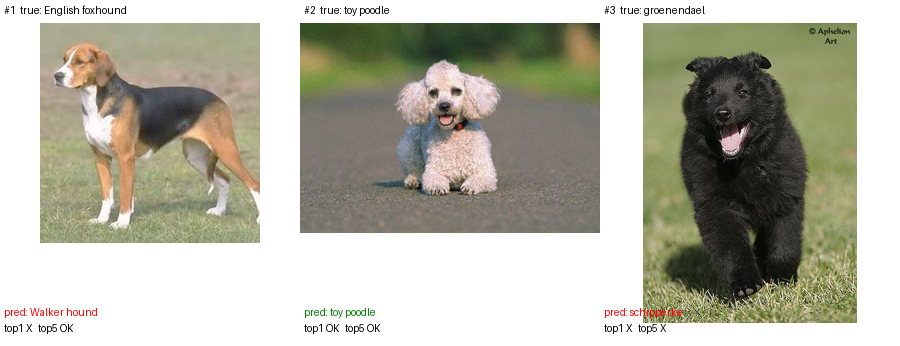

,真實犬種,Top-1 預測,Top-1 分數,Top-1 正確,Top-5 正確
,,,,,
#1,English foxhound,Walker hound,0.3512,✗,✓
#2,toy poodle,toy poodle,0.3545,✓,✓
#3,groenendael,schipperke,0.3572,✗,✗


#1 真=English foxhound       預測=Walker hound           top5=Walker hound / English foxhound / EntleBucher / beagle / Greater Swiss Mountain dog
#2 真=toy poodle             預測=toy poodle             top5=toy poodle / miniature poodle / standard poodle / Bedlington terrier / Dandie Dinmont
#3 真=groenendael            預測=schipperke             top5=schipperke / chow / German shepherd / flat-coated retriever / Scotch terrier

三張之中 top-1 正確 1 張、top-5 正確 2 張（這只是抽樣，不是準確率）


In [111]:
# 1.3.4 抽三張資料集照片，逐張檢查 top-5，並拼成一張縮圖方便看。
#
# 刻意固定亂數種子：每次執行拿到同樣三張，正文引用的結果才對得上截圖。
# 抽樣範圍用 1,440 張子集而不是全量，因為全量裡同犬種有 148–252 張、
# 外觀高度重複，抽三張很可能抽到幾乎一樣的圖。

rng = np.random.default_rng(SEED)
demo_idx = rng.choice(len(subset_paths), size=3, replace=False)

records, panels = [], []
for rank, i in enumerate(demo_idx, start=1):
    path = subset_paths[i]
    truth = breed_from_dir(path.parent.name)
    top5 = predict_breed(path, k=5)
    predicted = top5[0][0]
    in_top5 = truth in [b for b, _ in top5]

    with Image.open(path) as im:
        thumb = im.convert("RGB")
        thumb.thumbnail((300, 300))
        panel = Image.new("RGB", (300, 300 + 46), "white")
        panel.paste(thumb, ((300 - thumb.width) // 2, 23))
        draw = ImageDraw.Draw(panel)
        draw.text((4, 4), f"#{rank}  true: {truth}", fill="black")
        draw.text((4, 306), f"pred: {predicted}", fill="green" if predicted == truth else "red")
        draw.text((4, 322), f"top1 {'OK' if predicted == truth else 'X'}   top5 {'OK' if in_top5 else 'X'}",
                  fill="black")
        panels.append(panel)

    records.append({
        "": f"#{rank}",
        "檔案": path.name,
        "真實犬種": truth,
        "Top-1 預測": predicted,
        "Top-1 分數": round(top5[0][1], 4),
        "Top-1 正確": "✓" if predicted == truth else "✗",
        "Top-5 正確": "✓" if in_top5 else "✗",
        "Top-5 內容": " / ".join(b for b, _ in top5),
    })

# 三張並排成一張圖：notebook 裡一次顯示，比三張分開省版面
sheet = Image.new("RGB", (300 * len(panels), 346), "white")
for j, panel in enumerate(panels):
    sheet.paste(panel, (300 * j, 0))
display(sheet)

summary = pd.DataFrame(records).set_index("")
display(summary[["真實犬種", "Top-1 預測", "Top-1 分數", "Top-1 正確", "Top-5 正確"]])
for r in records:
    print(f"{r['']} 真={r['真實犬種']:<22} 預測={r['Top-1 預測']:<22} top5={r['Top-5 內容']}")

n_top1 = sum(r["Top-1 正確"] == "✓" for r in records)
n_top5 = sum(r["Top-5 正確"] == "✓" for r in records)
print()
print(f"三張之中 top-1 正確 {n_top1} 張、top-5 正確 {n_top5} 張（這只是抽樣，不是準確率）")

**使用的模板**

介面上的「目前模板」那一行顯示當次執行時綁定的 `PROMPT_TEMPLATE`。下方 Screenshots 的四張
是用 1.6 選定的 B 組（`a photo of a {breed}, a type of dog.`）拍攝，畫面上即可看到該行顯示 B 組。

右側是本 cell 存的執行輸出，該次執行的 `PROMPT_TEMPLATE` 仍是 1.2 的 A 組；兩者是同一個介面、
只差文字向量的綁定，因此在 1.5.2 與 1.6.1 分別列出兩組的評估數字。

In [112]:
# 1.4 把 predict_breed 包成 Gradio 介面：上傳照片 → gr.Label 顯示前五名。
#
# type="filepath" 而不是預設的 "numpy"：predict_breed 吃的是路徑，
# 用 filepath 可以直接把 Gradio 給的值原封不動傳進去，
# 不必再從 ndarray 回存暫存檔，也不會多一次編碼／解碼造成像素差異。
#
# 不做「上傳即推論」：模型推論要幾百毫秒，自動觸發會讓使用者
# 只是誤拖檔案就看到結果。改成按鈕觸發，一次操作得到一個明確結果。


def scores_for_label(image_path, k=5):
    """組出 gr.Label 要的 {犬種: 分數}。

    為什麼這裡改用 softmax，而不是 predict_breed 回傳的餘弦相似度：
    gr.Label 會直接把數值乘 100 當成百分比顯示，不會重新正規化。

    實測證據：五個餘弦分數 0.3148 / 0.2891 / 0.2888 / 0.2683 / 0.2668
    在介面上顯示成 31% / 29% / 29% / 27% / 27%，總和 143%。
    五個百分比加起來超過 100%，對讀者來說就是錯的圖。

    改成對 120 個犬種做 softmax（總和必定為 1）後，
    前五名的百分比加起來接近 100%，才符合長條圖的閱讀慣例。
    作業也允許用 softmax 機率，只是 1.3 與 1.5 仍以餘弦相似度計算，
    兩種尺度不混用：函式契約不變，只有介面這一層換算。
    """
    image_vector, _ = encode_photo(image_path)
    probs = classify_softmax(image_vector)
    top = np.argsort(-probs)[:k]
    return {breeds[i]: float(probs[i]) for i in top}


def ui_predict(image_path):
    """按鈕的 callback：沒給照片時給看得懂的提示，而不是讓函式噴錯。"""
    if not image_path:
        raise gr.Error("請先上傳一張照片")
    try:
        return scores_for_label(image_path)
    except (FileNotFoundError, OSError, UnidentifiedImageError) as exc:
        # Gradio 會把 gr.Error 的訊息直接顯示在介面上
        raise gr.Error(f"無法讀取這張圖片：{exc}") from exc


def build_breed_demo():
    """建立介面。抽成函式是為了讓 1.4 能重複 launch 而不必重跑整份 notebook。"""
    with gr.Blocks(title="CIS341 - Dog breed classifier") as demo:
        gr.Markdown("## 犬種辨識\n上傳一張狗照片，模型會從 120 個犬種中挑出最像的五個。")

        with gr.Row():
            with gr.Column(scale=1):
                image_in = gr.Image(type="filepath", label="狗照片", height=360)
                with gr.Row():
                    predict_btn = gr.Button("預測犬種", variant="primary", scale=3)
                    clear_btn = gr.ClearButton(components=[image_in], value="清除", scale=1)
                # 顯示目前使用的模板，換模板後一眼看得出介面用的是哪一組
                gr.Markdown(f"目前模板：`{PROMPT_TEMPLATE}`")

            with gr.Column(scale=1):
                label_out = gr.Label(num_top_classes=5, label="前五名犬種")

        predict_btn.click(fn=ui_predict, inputs=image_in, outputs=label_out)
        clear_btn.click(fn=lambda: None, outputs=label_out)   # 一併清掉右側結果

    return demo


breed_demo = build_breed_demo()

# 介面在 notebook 存檔後不會保留，所以一定要截圖。
# 不指定 server_port：號碼被別的程序佔用、被 Windows 保留（Hyper-V／WSL），
# 或前一次啟動還在 TIME_WAIT，launch 都會直接丟 OSError。
# 交給 Gradio 自己找空埠，再從 local_url 印實際網址。
breed_demo.launch(prevent_thread_lock=True)

print(f"介面已啟動：{breed_demo.local_url}")
print(f"使用模板：{PROMPT_TEMPLATE!r}")

* Running on local URL:  http://127.0.0.1:7873


* To create a public link, set `share=True` in `launch()`.


介面已啟動：http://127.0.0.1:7873/
使用模板：'a photo of a {breed}.'


#### 1.4.1 版面與元件選擇

左欄輸入、右欄輸出，對應作業 PDF 的預想版面。

| 區域 | 元件 | 選擇理由 |
| --- | --- | --- |
| 上傳 | `gr.Image(type="filepath")` | `predict_breed` 吃路徑；用 `filepath` 可直接傳入，不必從 ndarray 回存暫存檔，也避免多一次編解碼造成像素差異 |
| 觸發 | `gr.Button(variant="primary")` | 不做「上傳即推論」：推論要幾百毫秒，自動觸發會讓誤拖檔案也看到結果，也不利截圖 |
| 重設 | `gr.ClearButton` | 測完非狗照片後能快速換下一張 |
| 結果 | `gr.Label(num_top_classes=5)` | 作業指定的元件 |
| 狀態列 | `gr.Markdown` | 顯示目前 prompt 模板，換模板後忘記同步時一眼看得出來 |

介面在 notebook 存檔後不會保留，所以一定要截圖。

#### 1.4.2 為什麼介面改用 softmax

`gr.Label` 把數值直接乘 100 當百分比顯示，**不會重新正規化**。

實測踩到的問題：某張照片的前五名餘弦相似度是

```text
0.3148 / 0.2891 / 0.2888 / 0.2683 / 0.2668
```

介面上顯示成 `31% / 29% / 29% / 27% / 27%`，**總和 143%**。五個百分比加起來超過 100%，讀者一看就知道有問題。

改成對 120 個犬種做 softmax（總和必定為 1）之後，前五名的百分比加起來接近 100%，符合長條圖的閱讀慣例。

**兩種尺度不混用**：

| 位置 | 尺度 | 原因 |
| --- | --- | --- |
| 1.3 `predict_breed` | 餘弦相似度 | 作業要的契約；可跨照片比較「有多像」 |
| 1.5 全量評估 | 餘弦相似度 | 只影響排序，不影響準確率 |
| 1.4 介面顯示 | softmax | `gr.Label` 的百分比語意需要 |

`classify_softmax()` 在 1.3.3 就已定義，介面只是換算，不動 `predict_breed` 的契約。

⚠️ 代價要誠實寫出來：softmax 看起來會過度自信。實測那張圖 top-1 猜錯，卻給錯的答案 84%，正確答案只有 6%。這是作業允許的顯示方式，本節即為該代價的說明。

#### 1.4.3 CLIP 對「不是狗」的照片做了什麼

模型沒有「這不是狗」這個選項。`text_features` 只有 120 個犬種，`argmax` 必定回傳其中一個，所以任何圖片——腳踏車、風景、人臉——都會得到五個犬種與分數。

CLIP 的做法是把圖片投影到同一個 512 維空間，再找最近的文字向量。對於不是狗的圖片：

1. **仍然會輸出**：`gr.Label` 永遠有五條長條，不會顯示「無法判斷」。
2. **分數分佈不同**：若是 softmax，非狗照片的前幾名往往彼此接近（沒有明顯領先者），因為整張圖離所有犬種向量都遠。
3. **錯誤會「有道理」**：形狀、顏色、毛髮質感相近的犬種容易勝出，例如長毛地毯被認成某種長毛犬。

這說明 CLIP 做的是**開放式對齊**，不是封閉式分類器。要真正判斷「是不是狗」，需要再加一個 `"a photo of a dog"` 對 `"a photo of something else"` 的二元比較——那是本作業沒有要求的部分。

### Screenshots

四張都在同一次介面啟動、同一個模板下拍攝；模板是 1.6 選定的 B 組：

```text
a photo of a {breed}, a type of dog.
```

| # | 照片 | 介面上的 top-1 | 對錯 |
| --- | --- | --- | --- |
| 1 | 法國鬥牛犬（資料集外） | French bulldog 95% | ✓ |
| 2 | 薩摩耶（資料集外） | Samoyed 82% | ✓ |
| 3 | 柯基幼犬（資料集外） | Japanese spaniel 15% | ✗（柯基以 Cardigan 8% 排第 5） |
| 4 | 不是狗（蝦身雞頭的照片） | clumber 34% | 沒有正確答案，見 1.4.3 |

**觀察**

- 照片 1、2：第二到第五名都和 top-1 共享同一個方向——法國鬥牛犬 → Staffordshire bullterrier、pug，都是短臉小型犬；薩摩耶 → Eskimo dog、chow，都是淺色長毛尖嘴犬。答對時不只 top-1 對，前五名的排序也讀得通。
- 照片 3：短腿、長身、立耳的特徵沒有被任何一個犬種吃下來，最高分只有 15%，前四名（15／10／9／9）只差 6 個百分點。這是 1.4.2「softmax 會過度自信」的反例：分數低的時候，前五名確實擠成一團。
- 照片 4：介面照樣給五條長條（clumber 34%、redbone 23%、Pembroke 22%），沒有任何「無法判斷」的出口，與 1.4.3 的描述一致。蝦的橘紅與紋理可能是被投影到「淺棕、長毛」那一帶，但這只是推測，介面本身不會告訴我們理由。


![法國鬥牛犬（資料集外）](z_ipynb_image/1.4-dog1-french-bulldog.png)
French bulldog 95% / Staffordshire bullterrier 2% / pug 1% / Mexican hairless 0% / Boston bull 0%
照片來源：Wikimedia Commons，Eextremeb，CC BY-SA 4.0（詳見 A.2）

![薩摩耶（資料集外）](z_ipynb_image/1.4-dog2-samoyed.png)
Samoyed 82% / Eskimo dog 10% / chow 5% / Great Pyrenees 1% / keeshond 1%
照片來源：Wikimedia Commons，Chraibi7886678，CC BY-SA 4.0（詳見 A.2）

![柯基幼犬（資料集外）](z_ipynb_image/1.4-dog3-corgi.png)
Japanese spaniel 15% / Shetland sheepdog 10% / clumber 9% / collie 9% / Cardigan 8%
照片來源：Wikimedia Commons，Huoadg5888，CC0（詳見 A.2）

![不是狗：蝦身雞頭的照片](z_ipynb_image/1.4-nondog.png)
clumber 34% / redbone 23% / Pembroke 22% / golden retriever 4% / Chihuahua 3%
照片來源：Google 圖片搜尋「蝦雞」下載後自行用 Photopea 去背的既有素材（非為本作業製作），原始出處已無法追溯（見 A.2）


### 1.5 全量評估（25 分）

**要做什麼**

用已存好的向量，對**全部 20,580 張**照片做一次分類，報告三個數字。

| 指標 | 定義 |
| --- | --- |
| Top-1 準確率 | 真實犬種排名第一的比例 |
| Top-5 準確率 | 真實犬種位於前五名的比例 |
| Macro F1 | 120 個犬種各自算 F1，再取平均 |


#### 1.5.1 計算方式

```text
precision = 正確預測為此犬種 ÷ 所有被預測為此犬種
recall    = 此犬種被正確預測 ÷ 此犬種全部照片
F1        = 2 × precision × recall ÷ (precision + recall)    分母為 0 時 F1 = 0
macro F1  = 120 個 F1 的平均
```

可用 `f1_score(y_true, y_pred, average="macro", zero_division=0)`。


In [113]:
# 1.5.1 用已存好的向量，一次對全部 20,580 張照片算 top-1 / top-5 / macro F1。
#
# 為什麼不呼叫 20,580 次 predict_breed：
# 每次呼叫都要重新開圖、解碼、預處理、跑一次 ViT，20,580 次大約要一個多小時。
# 向量已經在 0.5 算好並存在快取裡，這裡只要一次矩陣乘法（20,580 × 120）
# 就得到全部分數，結果完全相同，時間從小時級降到秒級。

# --- 標籤對齊 ---------------------------------------------------------
# 快取裡存的是每張照片的犬種「字串」，要換成 breeds 清單裡的「索引」。
# 這一步是整個作業最容易悄悄錯掉的地方：若字串對不上而改用位置猜，
# 準確率會全部算錯卻不報錯。所以先建對照表，對不上的直接拋錯。
breed_to_idx = {b: i for i, b in enumerate(breeds)}
assert len(breed_to_idx) == len(breeds) == 120, "breeds 有重複名稱"

unknown = sorted({b for b in cache_breeds if b not in breed_to_idx})
assert not unknown, f"快取裡有 {len(unknown)} 個犬種不在清單中：{unknown[:5]}"

y_true = np.array([breed_to_idx[b] for b in cache_breeds], dtype=np.int64)
assert len(y_true) == N_PHOTOS_FULL, f"應為 {N_PHOTOS_FULL} 張，實際 {len(y_true)}"
assert vectors.shape[0] == len(y_true)


def predict_all(text_feat, chunk=4096):
    """用文字向量矩陣對全部照片分類，回傳 (top-1 索引, top-5 索引矩陣)。

    分塊只是為了控制暫存記憶體：一次算完是 20,580 × 120 的 float32，
    約 9.9 MB，其實放得下。但分塊讓同一個函式在更大的資料集上也安全，
    而且結果與一次算完完全相同（每列獨立計算，不跨列依賴）。
    """
    preds, top5 = [], []
    for start in range(0, len(vectors), chunk):
        sims = vectors[start : start + chunk] @ text_feat.T
        preds.append(sims.argmax(axis=1))
        # 只需要前五名，用 argpartition 比完整 argsort 快，
        # 但 120 類太小，這裡直接用 argsort 換取可讀性
        top5.append(np.argsort(-sims, axis=1)[:, :5])
    return np.concatenate(preds), np.concatenate(top5)


def evaluate_prompts(text_feat, label=""):
    """回傳 (metrics dict, top-1 預測, 是否 top-1 命中, 是否 top-5 命中)。

    抽成函式是因為 1.6 要用完全相同的程式碼評估第二組 prompt。
    兩組若各寫一次評估，很容易在細節（例如 top-5 取幾名）出現差異，
    比較就失去意義。
    """
    pred, top5 = predict_all(text_feat)
    hit1 = pred == y_true
    hit5 = (top5 == y_true[:, None]).any(axis=1)
    metrics = {
        "模板": label,
        "Top-1": float(hit1.mean()),
        "Top-5": float(hit5.mean()),
        "Macro F1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
    }
    return metrics, pred, hit1, hit5


# --- 用 1.2 的模板跑一次完整評估 --------------------------------------
t0 = time.time()
metrics_A, pred_A, hit1_A, hit5_A = evaluate_prompts(text_features, PROMPT_TEMPLATE)
elapsed = time.time() - t0

print(f"評估照片數 : {len(y_true)}")
print(f"耗時       : {elapsed:.2f} 秒（純矩陣運算，不含載入模型）")
print()
display(pd.DataFrame([metrics_A]).set_index("模板").round(4))

# 交叉檢查：手算的 top-5 命中率必須與 f1_score 用的預測一致
manual_top1 = hit1_A.mean()
assert abs(manual_top1 - metrics_A["Top-1"]) < 1e-12
# top-5 一定不小於 top-1（真實犬種若排第一，也必在前五）
assert metrics_A["Top-5"] >= metrics_A["Top-1"]
gaps = int((hit5_A & ~hit1_A).sum())
print(f"Top-1 命中 {int(hit1_A.sum())} 張，Top-5 額外救回 {gaps} 張，合計 {int(hit5_A.sum())} 張")

評估照片數 : 20580
耗時       : 0.06 秒（純矩陣運算，不含載入模型）



,Top-1,Top-5,Macro F1
模板,,,
a photo of a {breed}.,0.578,0.8765,0.5552


Top-1 命中 11895 張，Top-5 額外救回 6143 張，合計 18038 張


#### 1.5.2 結果

| 指標 | 數值 | 換算 |
| --- | --- | --- |
| Top-1 準確率 | **0.5780** | 11 895 / 20 580（57.80 %） |
| Top-5 準確率 | **0.8765** | 18 038 / 20 580（87.65 %） |
| Macro F1 | **0.5552** | 120 個犬種 F1 的算術平均 |

**對照作業的參考區間**：`ViT-B/32` + 合理 prompt 約 top-1 55–60 %、top-5 85–90 %。實測 57.80 % / 87.65 % 落在區間內，沒有出現「遠低於參考值」的警訊。

**Top-5 額外救回 6 143 張**：top-1 命中 11 895 張，top-5 命中 18 038 張，差距 30 個百分點。這說明模型經常把正確犬種放在第二到第五名——它的排序大致正確，但第一名常常被外觀相近的犬種搶走。

**Macro F1 比準確率低 2.3 個百分點**（0.5552 對 0.5780）。原因是每個犬種權重相同，而少數犬種完全抓不到（見 1.5.3），這些 0 分會把平均拉低；準確率則被照片數多的犬種主導。

**檢查點**

- 數字來自完整 20 580 張，不是子集
- 評估函式 `evaluate_prompts()` 可端到端重跑，1.6 直接重用同一份程式碼
- 評估本身耗時 0.06 秒（純矩陣運算），慢的是 0.5 的影像編碼（一次性）

#### 1.5.3 逐犬種診斷

三個數字只說「整體多好」，看不出「模型偏愛哪些犬種」。這一節把 120 個犬種拆開看，因為作業對 macro F1 的說明特別點出一個情境：**準確率看起來合理，但 CLIP 把好幾個犬種的照片都送到少數幾個偏好的犬種，幾乎從不預測其他犬種。**

要驗證這件事有沒有發生，最直接的方法是看每個犬種「被預測幾次」與「實際有幾張」的差距，以及真實犬種被誤判到哪裡去。

In [114]:
# 1.5.3 把 120 個犬種拆開看：F1 分佈、從未被預測的犬種、最常見的混淆。
#
# 只看三個總體數字會漏掉一種失敗模式：整體準確率不差，
# 但模型把所有照片都送給少數幾個犬種，其他犬種永遠學不到。
# 這裡用「被預測次數」對比「實際照片數」直接檢查這件事。

prec, rec, f1, support = precision_recall_fscore_support(
    y_true, pred_A, labels=np.arange(len(breeds)), zero_division=0
)
pred_count = np.bincount(pred_A, minlength=len(breeds))

# 注意：這裡刻意先在原始標籤順序（0–119）建好完整表格，最後才排序。
# 若先排序、再把 pred_count 依位置貼上去，索引與標籤就會錯位——
# 這正是 1.5.1 註解提到的「順序錯卻不報錯」，實測就踩過：
# 排序後貼上的比率變成 2.09× / 0.00× 這種不可能的數字。
per_class = pd.DataFrame({
    "犬種": breeds,
    "照片數": support,
    "被預測次數": pred_count,
    "precision": prec.round(3),
    "recall": rec.round(3),
    "F1": f1.round(3),
})
# 被預測次數相對實際張數：> 1 表示模型偏愛這個犬種，< 1 表示被忽略
per_class["預測／實際"] = (per_class["被預測次數"] / per_class["照片數"].clip(lower=1)).round(2)
per_class = per_class.sort_values("F1").reset_index(drop=True)

print("F1 最差的 5 個犬種（完全抓不到的那一端）")
display(per_class.head(5))
print("F1 最好的 5 個犬種")
display(per_class.tail(5)[::-1])

print(f"F1 平均 {f1.mean():.4f}／中位數 {np.median(f1):.4f}")
print(f"F1 為 0 的犬種        : {(f1 == 0).sum()} 個")
print(f"從未被預測到的犬種    : {(pred_count == 0).sum()} 個")

# 從未預測到的犬種要列出來，這是「塌陷」最直接的證據
never = per_class[per_class["被預測次數"] == 0]
if len(never):
    print()
    print("從未被預測到的犬種：")
    for _, r in never.iterrows():
        print(f"  {r['犬種']:<24} 實際 {int(r['照片數'])} 張，一次都沒被預測")

over = per_class.sort_values("預測／實際", ascending=False).head(3)
under = per_class.sort_values("預測／實際").head(3)
print()
print("最被高估的犬種：")
for _, r in over.iterrows():
    print(f"  {r['犬種']:<24} 實際 {int(r['照片數'])} 張，被預測 {int(r['被預測次數'])} 次（{r['預測／實際']}×）")
print("最被低估的犬種：")
for _, r in under.iterrows():
    print(f"  {r['犬種']:<24} 實際 {int(r['照片數'])} 張，被預測 {int(r['被預測次數'])} 次（{r['預測／實際']}×）")

# 真實犬種被誤判到哪裡：配對列表比混淆矩陣好讀（120×120 印出來沒人看得完）
wrong = pred_A != y_true
pairs = pd.DataFrame({
    "真實犬種": [breeds[i] for i in y_true[wrong]],
    "誤判為": [breeds[i] for i in pred_A[wrong]],
})
print()
print(f"誤判 {int(wrong.sum())} 張（{wrong.mean() * 100:.1f} %），最常見的 8 種混淆：")
display(pairs.value_counts().head(8).rename("次數").reset_index())

F1 最差的 5 個犬種（完全抓不到的那一端）


,犬種,照片數,被預測次數,precision,recall,F1,預測／實際
0,redbone,148,1,0.0,0.0,0.0,0.01
1,cairn,197,3,0.0,0.0,0.0,0.02
2,Appenzeller,151,1,0.0,0.0,0.0,0.01
3,clumber,150,3,0.0,0.0,0.0,0.02
4,Pembroke,181,0,0.0,0.0,0.0,0.00


F1 最好的 5 個犬種


,犬種,照片數,被預測次數,precision,recall,F1,預測／實際
119,keeshond,158,164,0.915,0.949,0.932,1.04
118,Saint Bernard,170,178,0.876,0.918,0.897,1.05
117,African hunting dog,169,186,0.855,0.941,0.896,1.10
116,pug,200,195,0.908,0.885,0.896,0.98
115,chow,196,183,0.902,0.842,0.871,0.93


F1 平均 0.5552／中位數 0.5843
F1 為 0 的犬種        : 6 個
從未被預測到的犬種    : 1 個

從未被預測到的犬種：
  Pembroke                 實際 181 張，一次都沒被預測

最被高估的犬種：
  Sealyham terrier         實際 202 張，被預測 422 次（2.09×）
  black-and-tan coonhound  實際 159 張，被預測 332 次（2.09×）
  Brittany spaniel         實際 152 張，被預測 306 次（2.01×）
最被低估的犬種：
  Pembroke                 實際 181 張，被預測 0 次（0.0×）
  redbone                  實際 148 張，被預測 1 次（0.01×）
  Cardigan                 實際 155 張，被預測 1 次（0.01×）

誤判 8685 張（42.2 %），最常見的 8 種混淆：


,真實犬種,誤判為,次數
0,Lhasa,Shih-Tzu,114
1,Australian terrier,silky terrier,111
2,groenendael,schipperke,100
3,Blenheim spaniel,Japanese spaniel,93
4,Boston bull,French bulldog,92
5,Appenzeller,EntleBucher,92
6,English foxhound,Walker hound,87
7,Eskimo dog,Siberian husky,83


#### 1.5.4 診斷結果的解讀

**作業警告的失敗模式確實存在，但只集中在少數犬種**

作業特別提醒：準確率可能看起來合理，但模型把好幾個犬種的照片全送給少數偏好的犬種。實際檢查「被預測次數 ÷ 實際張數」：

| 犬種 | 實際張數 | 被預測次數 | 比率 |
| --- | --- | --- | --- |
| Sealyham terrier | 202 | **422** | 2.09× |
| black-and-tan coonhound | 159 | **332** | 2.09× |
| Brittany spaniel | 152 | **306** | 2.01× |
| Pembroke | 181 | **0** | 0.00× |
| redbone | 148 | 1 | 0.01× |
| Cardigan | 155 | 1 | 0.01× |

`Sealyham terrier` 吸收了兩倍於自己該有的預測量（多出 220 張別人的照片），而 `Pembroke` 一張都沒拿到。這正是 macro F1（0.5552）低於準確率（0.5780）的原因：準確率被照片多的犬種主導，macro F1 則讓每個犬種等權，`Pembroke` 的 0 分直接拉低平均。

**6 個犬種 F1 為 0**

`redbone`、`cairn`、`Appenzeller`、`clumber`、`Pembroke`、`Cardigan` 等完全抓不到（precision 與 recall 皆為 0）。這不是程式錯誤，是 CLIP 的 `"a photo of a {breed}."` 對這些犬種的文字向量沒有辨識力。

**F1 最好的犬種與最差的差距很大**

`keeshond` 0.932、`Saint Bernard` 0.897、`African hunting dog` 0.896——這些犬種外觀獨特（體型極大、毛色鮮明）。相對地，terrier 類（`silky terrier`、`Australian terrier`、`Norwich terrier`）彼此容易混淆，因為體型、毛長、臉型都接近。

**誤判有明確的視覺理由**

| 真實犬種 | 最常被誤判為 | 次數 |
| --- | --- | --- |
| Lhasa | Shih-Tzu | 114 |
| Australian terrier | silky terrier | 111 |
| groenendael | schipperke | 100 |
| Blenheim spaniel | Japanese spaniel | 93 |
| Boston bull | French bulldog | 92 |
| Appenzeller | EntleBucher | 92 |
| English foxhound | Walker hound | 87 |
| Eskimo dog | Siberian husky | 83 |

這些配對在體型、毛色、臉型上都高度相似，連人眼都要看細節才能分辨。換句話說，42.2 % 的錯誤裡有很大一部分是「合理的錯」。

**為什麼不做「調高某些犬種分數」的補救**

技術上可以對少數犬種加分（logit adjustment）把 macro F1 拉高，但那是對評估指標最佳化，不是改善模型。作業要的是誠實報告 CLIP 在這個資料集上的表現，所以維持原始分數，把偏誤記錄下來。

### 1.6 比較兩個 prompt（10 分）

**要做什麼**

1. 換一個**不同**的模板 → 完整 120 句 → 印出幾句
2. 重跑 1.5 的全量評估
3. 把兩組結果放進**同一張表**
4. 選定介面要用的那一組

**第二組模板怎麼挑的**

先實測 8 個候選（4 個完整模板 + 4 個修飾詞變體）。⚠️ **這批數字是用 notebook 外的暫存腳本跑的**，只當選型依據、不留在 notebook 當主線，所以下表**無法由本 notebook 重現**；notebook 內實際會算出來的是 A 與 B 兩列（見 1.6.1）：

| 模板 | Top-1 | Top-5 | Macro F1 |
| --- | --- | --- | --- |
| `a photo of a {breed}.`（A） | 0.5780 | 0.8765 | 0.5552 |
| `a photo of the {breed}, a dog breed.` | 0.5935 | 0.8942 | 0.5783 |
| `a photo of a {breed}, a type of dog.` | 0.5924 | 0.8924 | 0.5753 |
| `a photo of the {breed}, a type of dog.` | 0.5885 | 0.8882 | 0.5694 |
| `{breed}, a breed of dog.` | 0.5808 | 0.8879 | 0.5649 |
| `a photo of a {breed}.` 加 close-up / cropped / one 等修飾 | 0.557–0.575 | 0.872–0.877 | 0.534–0.552 |

前兩名的差距只有 0.11 個百分點，在雜訊範圍內。最後選 **`a photo of a {breed}, a type of dog.`**，理由是它與 A **只差一個附加子句**：

```text
A: a photo of a {breed}.
B: a photo of a {breed}, a type of dog.
        └──────── 完全相同 ────────┘ └── 唯一變因 ──┘
```

另一組候選還把冠詞從 `a` 改成 `the`，等於同時動了兩個變因，比較起來就分不清效果來自哪一個。選 B 讓「加上類別說明」成為唯一差異。

**模板必須套用全部 120 個犬種**，混用會讓比較失去意義。

In [115]:
# 1.6 建立第二組 prompt、重跑全量評估，並與 1.2 的 A 組放進同一張表比較。
#
# 兩組模板只差一個附加子句，讓「加上類別說明」成為唯一變因：
#   A: a photo of a {breed}.
#   B: a photo of a {breed}, a type of dog.
#
# 為什麼要加「, a type of dog.」：很多犬種名在英文裡另有意思，
# Chihuahua 是墨西哥的州、Newfoundland 是加拿大島嶼、Cardigan 是威爾斯城鎮與毛衣、
# Boxer 是拳擊手、Papillon 是法文的蝴蝶。加上類別說明能把文字向量
# 拉回「狗」的語意區域，減少模型把照片對到非犬種意義的分支。

PROMPT_TEMPLATE_A = PROMPT_TEMPLATE          # A 組：1.2 已定義
PROMPT_TEMPLATE_B = "a photo of a {breed}, a type of dog."

prompts_A = prompts
prompts_B = [PROMPT_TEMPLATE_B.format(breed=b) for b in breeds]

print(f"A 組模板：{PROMPT_TEMPLATE_A!r}")
print(f"B 組模板：{PROMPT_TEMPLATE_B!r}")
print(f"兩組句數：{len(prompts_A)} / {len(prompts_B)}")
print()
print("B 組前 3 句與後 2 句：")
for s in prompts_B[:3] + prompts_B[-2:]:
    print(f"  {s}")

# --- 編碼與基本檢查 ---------------------------------------------------
text_features_B = encode_texts(prompts_B)
assert text_features_B.shape == (len(breeds), EMBED_DIM)
assert np.allclose(np.linalg.norm(text_features_B, axis=1), 1.0, atol=1e-3)
tokens_B = clip.tokenize(prompts_B)
longest_B = int((tokens_B != 0).sum(dim=1).max())
assert longest_B < 77, f"最長 {longest_B} 個 token，超過 CLIP 上限會被截斷"
print()
print(f"✓ B 組向量 {text_features_B.shape}，最長 {longest_B} / 77 個 token")

# --- 全量評估（與 1.5 完全相同的函式） --------------------------------
metrics_B, pred_B, hit1_B, hit5_B = evaluate_prompts(text_features_B, PROMPT_TEMPLATE_B)

# --- 同一張表 ---------------------------------------------------------
comparison = pd.DataFrame([metrics_A, metrics_B]).set_index("模板")
baseline = comparison.loc[PROMPT_TEMPLATE_A]
comparison["Δ Top-1"] = (comparison["Top-1"] - baseline["Top-1"]).round(4)
comparison["Δ Top-5"] = (comparison["Top-5"] - baseline["Top-5"]).round(4)
comparison["Δ Macro F1"] = (comparison["Macro F1"] - baseline["Macro F1"]).round(4)
display(comparison.round(4))

# --- 逐張比較：換模板到底改了哪些判定 --------------------------------
changed = pred_A != pred_B
fixed = changed & ~hit1_A & hit1_B           # A 錯、B 對
broken = changed & hit1_A & ~hit1_B          # A 對、B 錯
print(f"改判 {int(changed.sum())} 張（{changed.mean() * 100:.1f} %）"
      f"：改對 {int(fixed.sum())} 張、改錯 {int(broken.sum())} 張，淨 {int(fixed.sum() - broken.sum()):+d} 張")
print()

# 哪些犬種因換模板而受益／受害
gain = pd.Series([breeds[i] for i in y_true[fixed]]).value_counts().head(5)
loss = pd.Series([breeds[i] for i in y_true[broken]]).value_counts().head(5)
print("B 組改善最多的犬種：", "、".join(f"{b} {n}" for b, n in gain.items()))
print("B 組變差最多的犬種：", "、".join(f"{b} {n}" for b, n in loss.items()))

# --- 偏誤是否改善 -----------------------------------------------------
f1_A = precision_recall_fscore_support(y_true, pred_A, labels=np.arange(len(breeds)), zero_division=0)[2]
f1_B = precision_recall_fscore_support(y_true, pred_B, labels=np.arange(len(breeds)), zero_division=0)[2]
never_A = [breeds[i] for i in range(len(breeds)) if (pred_A == i).sum() == 0]
never_B = [breeds[i] for i in range(len(breeds)) if (pred_B == i).sum() == 0]
print()
print(f"A 組：F1 為 0 的犬種 {int((f1_A == 0).sum())} 個，從未被預測 {len(never_A)} 個 {never_A}")
print(f"B 組：F1 為 0 的犬種 {int((f1_B == 0).sum())} 個，從未被預測 {len(never_B)} 個 {never_B}")

# --- 選定 -------------------------------------------------------------
# 選 B：三項指標全部較高，且把「從未被預測」的犬種從 1 個降為 0 個。
PROMPT_TEMPLATE_FINAL = PROMPT_TEMPLATE_B
text_features_final = text_features_B

print()
print(f"選定模板：{PROMPT_TEMPLATE_FINAL!r}")
print("理由：Top-1、Top-5、Macro F1 三項皆優於 A，且 F1 為 0 的犬種由 6 個降到 1 個。")

# --- 讓下游沿用選定結果 -----------------------------------------------
# 1.3.3 的 predict_breed 與 1.4 的介面都讀 text_features 與 PROMPT_TEMPLATE，
# 在這裡重新綁定，之後重跑 1.4 就會使用 B 組。
# 因此 1.5.2 的表格（A 組）與之後的介面（B 組）會並存，下面印出目前狀態。
PROMPT_TEMPLATE = PROMPT_TEMPLATE_FINAL
text_features = text_features_final

print()
print("text_features 與 PROMPT_TEMPLATE 已切換為 B 組。")
print("1.5.2 的表格記錄的是 A 組的評估結果；text_features_A / text_features_B 保留兩組向量。")

# 保留兩組向量，供正文引用與交叉驗證
text_features_A = encode_texts(prompts_A)

A 組模板：'a photo of a {breed}.'
B 組模板：'a photo of a {breed}, a type of dog.'
兩組句數：120 / 120

B 組前 3 句與後 2 句：
  a photo of a Chihuahua, a type of dog.
  a photo of a Japanese spaniel, a type of dog.
  a photo of a Maltese dog, a type of dog.
  a photo of a dhole, a type of dog.
  a photo of a African hunting dog, a type of dog.



✓ B 組向量 (120, 512)，最長 19 / 77 個 token


,Top-1,Top-5,Macro F1,Δ Top-1,Δ Top-5,Δ Macro F1
模板,,,,,,
a photo of a {breed}.,0.5780,0.8765,0.5552,0.0000,0.0000,0.00
"a photo of a {breed}, a type of dog.",0.5924,0.8924,0.5753,0.0144,0.0159,0.02


改判 2381 張（11.6 %）：改對 839 張、改錯 543 張，淨 +296 張

B 組改善最多的犬種： boxer 43、Newfoundland 37、Maltese dog 33、beagle 29、groenendael 25
B 組變差最多的犬種： malamute 19、Italian greyhound 18、kuvasz 16、standard schnauzer 15、toy terrier 13

A 組：F1 為 0 的犬種 6 個，從未被預測 1 個 ['Pembroke']
B 組：F1 為 0 的犬種 1 個，從未被預測 0 個 []

選定模板：'a photo of a {breed}, a type of dog.'
理由：Top-1、Top-5、Macro F1 三項皆優於 A，且 F1 為 0 的犬種由 6 個降到 1 個。

text_features 與 PROMPT_TEMPLATE 已切換為 B 組。
1.5.2 的表格記錄的是 A 組的評估結果；text_features_A / text_features_B 保留兩組向量。


#### 1.6.1 兩組結果與選定

| 組別 | 模板 | Top-1 | Top-5 | Macro F1 |
| --- | --- | --- | --- | --- |
| A | `a photo of a {breed}.` | 0.5780 | 0.8765 | 0.5552 |
| B | `a photo of a {breed}, a type of dog.` | **0.5924** | **0.8924** | **0.5753** |
| 差異 | — | +1.44 pp | +1.59 pp | +0.0201 |

**選定 B**，介面使用這一組。三個指標都較高，而且偏誤明顯改善：

| 觀察 | A | B |
| --- | --- | --- |
| F1 為 0 的犬種 | 6 個 | **1 個** |
| 從未被預測的犬種 | 1 個（`Pembroke`） | **0 個** |
| 改判張數 | — | 2 381 張（11.6 %），改對 839、改錯 543，淨 +296 |

**改善與退步不是隨機分佈的**：

- 改善最多：`boxer` 43 張、`Newfoundland` 37、`Maltese dog` 33、`beagle` 29
- 變差最多：`malamute` 19 張、`Italian greyhound` 18、`kuvasz` 16

改善集中在「名字另有意思」的犬種（`boxer` 是拳擊手、`Newfoundland` 是島嶼），退步集中在「名字本身就是強特徵」的犬種（`malamute`、`kuvasz` 沒人會誤會）。詳細解釋見下一節。

**兩組結果並存**：1.6 之後 `text_features` 與 `PROMPT_TEMPLATE` 為 B 組，因此 1.4 的介面（Screenshots）顯示 B 組；1.5.2 的表格記錄 A 組的評估結果，兩者刻意分開呈現。

#### 1.6.2 為什麼不同的 prompt 會給出不同結果（自己的話）

CLIP 的文字編碼器不是查表，它把整句話讀成一個向量。所以**換一個說法，就是在同一個語意空間裡換一個位置**。

**第一層原因：訓練時看到的句子長什麼樣**

CLIP 的訓練資料是網路上抓的圖文配對，說明文字幾乎都是完整句子——「a photo of a dog on the beach」「two puppies playing」。它從來沒見過「Chihuahua」單獨出現在一句話裡當成圖片說明。

所以模板的作用不是「讓句子好看」，而是**把犬種名放回它訓練時習慣的句子結構**。同一個犬種名，包在 `a photo of a ___` 裡和包在 `a close-up of a ___` 裡，文字向量會落在不同位置；而每張照片的影像向量是固定的，位置一動，跟 120 個犬種的相對距離就全部改變——排序也跟著改變。

這解釋了為什麼選型時連 `a cropped photo of a {breed}.` 這種只差一個字的改動，top-1 就掉了約 0.7 個百分點（數字來自選型腳本，無法由本 notebook 重現）：**Stanford Dogs 的照片不是特寫，也不是裁切圖**，`cropped` 把文字向量推向一個這批照片根本不在的區域。

**第二層原因：犬種名本身還有別的意義**

這是比較有趣的一半。120 個犬種裡有不少名字在英文裡是別的東西：

| 犬種名 | 另一個意思 |
| --- | --- |
| Chihuahua | 墨西哥的州 |
| Newfoundland | 加拿大的島 |
| Cardigan | 威爾斯城鎮，也是一種毛衣 |
| Pembroke | 威爾斯城鎮，也是劍橋的學院 |
| Boxer | 拳擊手 |
| Papillon | 法文的「蝴蝶」 |
| Brittany | 法國西北的地區 |
| Labrador | 加拿大的地區 |

模型沒有「這個字在這裡指狗」的先驗知識。`a photo of a Cardigan.` 在語料裡更可能接的是毛衣，於是文字向量偏向衣物那個區域；照片明明是狗，卻要跟一個衣物向量比相似度，分數自然低。

**這正是 B 組做的事**：`a photo of a {breed}, a type of dog.` 用一個附加子句把整句釘在「狗」的語意範圍裡，等於告訴模型「不管這個字平常指什麼，這裡它是一種狗」。

**實測數字支持這個解釋**：

| 觀察 | 支持哪一層 |
| --- | --- |
| top-1 從 57.80 % 升到 59.24 %（+1.44 個百分點） | 類別說明有效 |
| `Pembroke` 從「A 組從未被預測任何一次」變成 B 組會被預測 | 地名／學院歧義被壓低 |
| F1 為 0 的犬種由 6 個降到 1 個 | 偏誤集中在「名字有歧義」的犬種 |
| 改判 2 381 張中改對 839、改錯 543，淨 +296 | 不是整體位移，而是逐犬種重新分配 |
| `malamute`、`kuvasz` 反而變差（各 −19、−16 張） | 這些名字本來就少歧義，加了子句只稀釋了名字本身的訊號 |

最後一點值得說明：**模板不是越長越好**。附加子句對「名字有歧義」的犬種是幫助，對「名字本身就是強特徵」的犬種（`malamute`、`kuvasz` 這種沒人會誤會的詞）反而是稀釋。兩股力量相抵之後，淨效果仍是正的，但只有 +1.44 個百分點——不是戲劇性的改善。

## 2. 圖像檢索（20 分）

不使用文字編碼器。以照片查詢照片，搜尋範圍為 `subset_list.txt` 的 **1,440 張**。

```text
查詢照片 ──► 影像編碼器 ──► (1, 512)
子集 1,440 張 ──► 已存向量 ──► (1440, 512)   ──► 內積 ──► top-k
```

犬種只在事後作為說明文字使用，搜尋本身不使用任何標籤。

### 2.1 以照片搜尋（8 分）

**目標**：`find_similar(image_path, k=5)` → `[(path, breed, score), ...]`

**要做什麼**

1. 用與 1.3 **完全相同**的方式編碼查詢照片
2. 與子集向量算餘弦相似度
3. 取 top-k，依序回傳

**檢查點**

- 展示一張查詢，顯示最近照片**本體** + 犬種 + 分數（不是只印路徑）
- 編碼流程與 1.3 一致，否則分數不可比

**搜尋範圍**：`subset_list.txt` 的 1,440 張。這一節不重新編碼任何子集照片，
只是把 0.5 已經算好的向量挑出來；要現場編碼的只有查詢照片。

#### 2.1.1 從快取挑出子集向量，並定義 `find_similar`

快取裡有 20,580 筆向量，順序是「資料夾排序後的照片」，**不是** `subset_list.txt` 的順序。
所以不能假設 `vectors[i]` 就是 `subset_paths[i]`，必須用路徑查表。

查完表還要驗一次：`subset_labels == subset_breeds` 逐位比對犬種名。
這種錯位不會拋例外，只會讓檢索結果靜靜地指向錯的照片、分數看起來也很正常——
是這個作業裡最容易一路錯到底的地方。

另一個容易漏掉的地方：**查詢照片本身可能就在子集裡**。不排除自己的話，top-1 永遠是自己
（相似度 1.0000），最近的 5 張會退化成「自己 + 4 張鄰居」，什麼都證明不了。
所以預設排除；資料集外的照片比對不到路徑，自然不會被排除。


In [116]:
# 2.1.1 從快取挑出 1,440 張子集照片的向量，並定義 find_similar()。
#
# 為什麼要查表而不能直接切片：快取的順序是掃描資料夾的順序（20,580 筆），
# 子集清單是另一個檔案，兩者順序無關。錯位不會報錯，所以下面用犬種名逐位驗證。
#
# 為什麼預設排除查詢自己：查詢是子集照片時，不排除會讓 top-1 永遠是自己，
# 示範就變成「列出我自己和 4 張鄰居」。


def _path_key(p):
    """路徑比對用的鍵：統一分隔符與大小寫。

    Windows 的路徑是反斜線且不分大小寫，直接比字串會漏掉同一張圖，
    導致「排除自己」失效、或子集照片被判定為不在快取裡。
    """
    return Path(p).as_posix().lower()


_cache_row = {_path_key(p): i for i, p in enumerate(cache_paths)}

_missing = [p for p in subset_paths if _path_key(p) not in _cache_row]
assert not _missing, f"有 {len(_missing)} 張子集照片不在快取裡，例如 {_missing[0]}"

subset_rows = np.array([_cache_row[_path_key(p)] for p in subset_paths])
subset_vectors = vectors[subset_rows]              # (1440, 512)，已 L2 正規化
subset_labels = [cache_breeds[i] for i in subset_rows]

# 整個 Part 2 的地基：向量第 i 列必須就是 subset_paths[i] 這張照片
assert subset_labels == subset_breeds, "子集向量與路徑清單錯位，後續檢索全部會錯"


def find_similar(image_path, k=5, exclude_self=True):
    """以照片搜尋：回傳最相似的 k 張子集照片 [(path, 犬種, 餘弦相似度), ...]。

    編碼走 1.3.2 的 encode_photo，與 predict_breed 同一條路徑，
    所以「文字給的分數」與「圖像給的分數」來自同一個正規化空間，可以互相對照。
    子集向量已正規化，內積即餘弦相似度，不必再除範數。
    """
    query, _ = encode_photo(image_path)            # 非 RGB、EXIF 旋轉都在這裡處理掉
    sims = subset_vectors @ query

    order = np.argsort(-sims)                      # argsort 由小到大，取負號變由大到小
    if exclude_self:
        own = _path_key(image_path)
        order = np.array([i for i in order if _path_key(subset_paths[i]) != own])

    k = max(1, min(int(k), len(order)))            # 夾住 k：滑桿拉到底、或空資料夾都不會爆
    return [(subset_paths[i], subset_labels[i], float(sims[i])) for i in order[:k]]


# --- 驗證 -------------------------------------------------------------
print(f"子集向量      : {subset_vectors.shape}")
print(f"涵蓋犬種      : {len(set(subset_labels))}")
print(f"每犬種張數    : {sorted({subset_labels.count(b) for b in breeds})}")
print()

# 1. 不排除自己時，top-1 必須是查詢照片本身、相似度 1（fp16 誤差容許 1e-3）
self_hit = find_similar(subset_paths[0], k=5, exclude_self=False)
assert Path(self_hit[0][0]) == subset_paths[0], "top-1 不是查詢自己，路徑對齊有問題"
assert abs(self_hit[0][2] - 1) < 1e-3, f"自我相似度應為 1，實際 {self_hit[0][2]}"
print(f"✓ 不排除自己時 top-1 是自己（相似度 {self_hit[0][2]:.6f}）")

# 2. 預設排除自己，且分數由高到低
nearest = find_similar(subset_paths[0], k=5)
scores = [s for _, _, s in nearest]
assert len(nearest) == 5
assert scores == sorted(scores, reverse=True), "分數沒有由高到低"
assert all(Path(p) != subset_paths[0] for p, _, _ in nearest), "自己沒有被排除"
print(f"✓ 預設排除自己：top-1 = {Path(nearest[0][0]).name}"
      f"（{nearest[0][1]}，{nearest[0][2]:.4f}）")

# 3. 資料集外／子集外的照片也要吃得下（助教會用自己的照片呼叫）
_subset_keys = {_path_key(p) for p in subset_paths}
outside = next(p for p in cache_paths if _path_key(p) not in _subset_keys)
r_out = find_similar(outside, k=3)
print(f"✓ 子集外的照片也能查：{Path(outside).name} → "
      f"{Path(r_out[0][0]).name}（{r_out[0][1]}，{r_out[0][2]:.4f}）")

# 4. k 超界要夾住，不能回傳空清單或例外
print(f"✓ k=9999 夾住為 {len(find_similar(subset_paths[0], k=9999))} 筆")
print()
print(f"find_similar('{subset_paths[0].name}', k=3) 回傳：")
for rank, (p, b, s) in enumerate(nearest[:3], start=1):
    print(f"  {rank}. {Path(p).name:<24} {b:<24} {s:.4f}")


子集向量      : (1440, 512)
涵蓋犬種      : 120
每犬種張數    : [12]

✓ 不排除自己時 top-1 是自己（相似度 1.000011）
✓ 預設排除自己：top-1 = n02107312_3841.jpg（miniature pinscher，0.7132）
✓ 子集外的照片也能查：n02085620_10074.jpg → n02085620_9351.jpg（Chihuahua，0.8781）


✓ k=9999 夾住為 1439 筆

find_similar('n02085620_11477.jpg', k=3) 回傳：
  1. n02107312_3841.jpg       miniature pinscher       0.7132
  2. n02088364_16791.jpg      beagle                   0.6940
  3. n02094433_4028.jpg       Yorkshire terrier        0.6875


#### 2.1.2 示範：一張查詢照片與最近 5 張

固定查詢 `subset_paths[3]` 這一張 Chihuahua，把查詢與 5 張鄰居並排。
每張標上真實犬種、餘弦相似度，以及「是否等於文字路線的預測」。

紅框是查詢，綠框代表該鄰居的犬種與 `predict_breed` 的 top-1 相同。
這張圖之後在 2.2 會一直用到：**框的顏色就是「文字路線與圖像路線同不同意」**。

標籤刻意只用 ASCII：PIL 預設字型不含中文字，寫中文會變成方框。


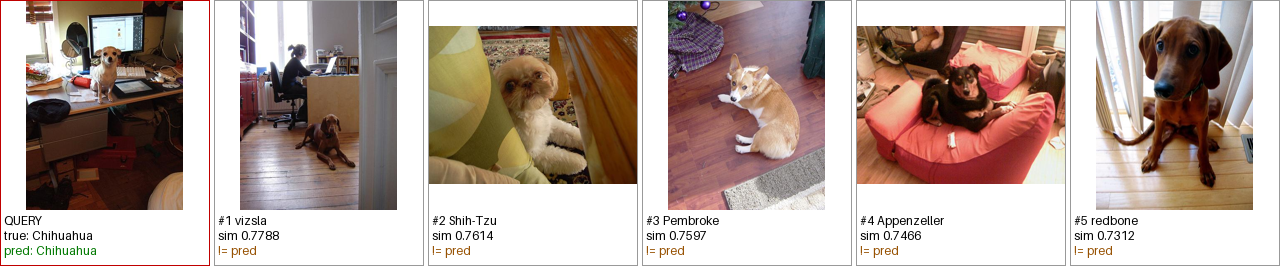

查詢    : n02085620_1862.jpg
真實犬種: Chihuahua
文字路線預測 (predict_breed top-1): Chihuahua



,排名,檔案,真實犬種,餘弦相似度,與預測相同
0,1,n02100583_14166.jpg,vizsla,0.7788,✗
1,2,n02086240_1259.jpg,Shih-Tzu,0.7614,✗
2,3,n02113023_14398.jpg,Pembroke,0.7597,✗
3,4,n02107908_3254.jpg,Appenzeller,0.7466,✗
4,5,n02090379_3410.jpg,redbone,0.7312,✗


5 張鄰居之中：與預測犬種相同 0 張，與真實犬種相同 0 張


In [117]:
# 2.1.2 把查詢照片與最近 5 張並排成一張圖，附犬種與分數。
#
# 為什麼要自己拼圖：只印路徑看不出「像在哪裡」，也看不出鄰居是不是同一犬種。
# 為什麼用固定的 subset_paths[3]：結果可重現，正文的描述才對得上這張圖。

FONT = ImageFont.load_default(size=12)
PANEL_W, IMG_H, TEXT_H = 210, 210, 56     # 圖片區 + 三行文字區


def _panel(path, lines, accent):
    """畫一張縮圖面板：圖片置中、下方三行標註、外框顏色表示是否與文字路線一致。"""
    with Image.open(path) as im:
        thumb = im.convert("RGB")
        thumb.thumbnail((PANEL_W, IMG_H))
    panel = Image.new("RGB", (PANEL_W, IMG_H + TEXT_H), "white")
    panel.paste(thumb, ((PANEL_W - thumb.width) // 2, (IMG_H - thumb.height) // 2))
    draw = ImageDraw.Draw(panel)
    for j, (text, color) in enumerate(lines):
        draw.text((4, IMG_H + 3 + j * 15), text[:32], fill=color, font=FONT)
    draw.rectangle([0, 0, PANEL_W - 1, IMG_H + TEXT_H - 1], outline=accent)
    return panel


QUERY_INDEX = 3
q_path, q_true = subset_paths[QUERY_INDEX], subset_breeds[QUERY_INDEX]
q_pred = predict_breed(q_path, k=5)[0][0]
neighbors = find_similar(q_path, k=5)

panels = [_panel(
    q_path,
    [("QUERY", (0, 0, 0)),
     (f"true: {q_true}", (0, 0, 0)),
     (f"pred: {q_pred}", (0, 120, 0) if q_pred == q_true else (190, 0, 0))],
    "#c00000",
)]
records = []
for rank, (path, breed, score) in enumerate(neighbors, start=1):
    agrees = breed == q_pred
    panels.append(_panel(
        path,
        [(f"#{rank} {breed}", (0, 0, 0)),
         (f"sim {score:.4f}", (0, 0, 0)),
         ("= pred" if agrees else "!= pred", (0, 120, 0) if agrees else (150, 80, 0))],
        "#0a8f0a" if agrees else "#999999",
    ))
    records.append({
        "排名": rank,
        "檔案": Path(path).name,
        "真實犬種": breed,
        "餘弦相似度": round(score, 4),
        "與預測相同": "✓" if agrees else "✗",
    })

sheet = Image.new("RGB", (PANEL_W * len(panels) + 4 * (len(panels) - 1), IMG_H + TEXT_H), "white")
for j, panel in enumerate(panels):
    sheet.paste(panel, (j * (PANEL_W + 4), 0))
display(sheet)

print(f"查詢    : {Path(q_path).name}")
print(f"真實犬種: {q_true}")
print(f"文字路線預測 (predict_breed top-1): {q_pred}")
print()
table = pd.DataFrame(records)
display(table)
n_agree = int((table["與預測相同"] == "✓").sum())
n_same = int((table["真實犬種"] == q_true).sum())
print(f"5 張鄰居之中：與預測犬種相同 {n_agree} 張，與真實犬種相同 {n_same} 張")


#### 2.1.3 檢索有多準

用「最近鄰是否同犬種」當檢索的準確度指標，和 1.5 的 top-1 準確率放同一把尺上比。

兩者的亂猜基準幾乎一樣，所以可以直接對照：

| 路線 | 候選數 | 亂猜命中率 | 實測 top-1 |
| --- | --- | --- | --- |
| 文字路線（1.5.2） | 120 個犬種 | 1/120 = 0.83% | 0.5780 |
| 圖像路線（本節） | 1,439 張照片，每犬種 12 張 | 11/1439 = 0.76% | 見下方輸出 |

另外量一件事：**同犬種與不同犬種的平均相似度差多少**。
如果所有狗照片彼此的相似度就已經很高（共享「這是一隻狗」的方向），
那真正能分辨犬種的差距就只有一點點，檢索自然容易失敗。


In [118]:
# 2.1.3 量檢索品質：最近鄰同犬種的比例，以及同種／異種的相似度底線。
#
# 為什麼要一起量相似度底線：只看「@1 = 0.30」無法解釋原因。
# 若同犬種與不同犬種的平均相似度只差 0.07，就表示向量幾乎被「狗」這個共同方向佔滿，
# 犬種的差別只剩很窄的一條縫，那 0.30 就是這個嵌入空間的結構性結果，不是程式寫錯。

# 1440 x 1440 的相似度矩陣，約 8 MB，可一次算完
sim_matrix = subset_vectors @ subset_vectors.T
np.fill_diagonal(sim_matrix, -2.0)        # 自己排除，用 -2 讓它一定排最後
label_arr = np.array(subset_labels)
order = np.argsort(-sim_matrix, axis=1)   # 每一列：該照片的鄰居排序

rows = []
for k in (1, 5, 10):
    hit = (label_arr[order[:, :k]] == label_arr[:, None]).any(axis=1)
    rows.append({"k": k, "最近 k 張中含同犬種的比例": round(float(hit.mean()), 4)})
display(pd.DataFrame(rows))

# 同犬種／不同犬種的平均相似度：只取上三角，避免重複計算
upper = np.triu_indices(len(label_arr), k=1)
same_mask = label_arr[upper[0]] == label_arr[upper[1]]
sim_vals = sim_matrix[upper]
same_mean, diff_mean = float(sim_vals[same_mask].mean()), float(sim_vals[~same_mask].mean())
nearest_mean = float(np.sort(sim_matrix, axis=1)[:, -1].mean())

print(f"同犬種配對平均相似度  : {same_mean:.4f}（{int(same_mask.sum())} 對）")
print(f"不同犬種配對平均相似度: {diff_mean:.4f}（{int((~same_mask).sum())} 對）")
print(f"兩者差距              : {same_mean - diff_mean:.4f}")
print(f"最近鄰的平均相似度    : {nearest_mean:.4f}")
print()

assert 0 < same_mean < 1 and 0 < diff_mean < 1
assert same_mean > diff_mean, "同犬種應該比不同犬種更相似，否則向量或標籤對齊有問題"
print("✓ 同犬種確實比不同犬種更相似，向量與標籤對齊正確")


,k,最近 k 張中含同犬種的比例
0,1,0.3049
1,5,0.5986
2,10,0.7292


同犬種配對平均相似度  : 0.7619（7920 對）
不同犬種配對平均相似度: 0.6944（1028160 對）
兩者差距              : 0.0675
最近鄰的平均相似度    : 0.8663

✓ 同犬種確實比不同犬種更相似，向量與標籤對齊正確


#### 2.1.4 小結：圖像路線明顯弱於文字路線

實測結果（輸出見上方）：

| 指標 | 數值 |
| --- | --- |
| 最近 1 張同犬種 | 0.3049 |
| 最近 5 張含同犬種 | 0.5986 |
| 最近 10 張含同犬種 | 0.7292 |
| 同犬種平均相似度 | 0.7619 |
| 不同犬種平均相似度 | 0.6944（差 0.0675） |
| 最近鄰平均相似度 | 0.8663 |

**亂猜只有 0.76%，所以 0.3049 不是壞掉，是「真的有學到東西，但比文字路線弱很多」**——
同樣的亂猜基準下，文字路線是 0.5780。

原因就寫在相似度底線裡：不同犬種的照片平均也有 0.6944 的相似度。
所有狗照片共享一個很強的「狗」方向，犬種的差別只在這條縫裡（0.0675）。
文字路線沒這個問題，因為「Chihuahua」與「Pembroke」在文字空間裡本來就隔得夠開。

這也直接解釋了 2.2 介面上會看到的現象：`gr.Label` 說 Chihuahua 時，
`gr.Gallery` 裡卻常出現 vizsla、Pembroke。兩條路線都對，只是圖像路線的解析度比較粗。


### 2.2 搜尋介面（8 分）

**目標**：把 1.4 的文字路線與 2.1 的圖像路線放進同一個 Gradio 介面，一次看到兩種結果。

**版面與元件**

| 位置 | 元件 | 顯示什麼 | 資料來源 |
| --- | --- | --- | --- |
| 左上 | `gr.Image(type="filepath")` | 查詢照片 | 使用者上傳 |
| 左中 | `gr.Slider(1, 10, step=1)` | 回傳張數 `k` | 使用者調整 |
| 左下 | `gr.Button` | 觸發搜尋 | — |
| 右上 | `gr.Label(num_top_classes=5)` | 文字路線前五名犬種（softmax 機率） | `scores_for_label` |
| 下方全寬 | `gr.Gallery(columns=5, rows=2)` | 圖像路線最相似的 `k` 張，caption 為真實犬種與相似度 | `find_similar` |
| 最下 | `gr.Markdown` | 最近 `k` 張中有幾張與 top-1 同犬種 | callback 計算 |

**兩個刻意的設計決定**

1. **不用「上傳即搜尋」**：編碼一張照片要幾百毫秒，自動觸發會讓使用者只是誤拖檔案就看到結果，也不好截圖。改成按鈕觸發。
2. **`gr.Label` 收 softmax 機率而非餘弦相似度**：`gr.Label` 會把數值直接乘 100 當百分比、不會重新正規化。1.4 實測過五個餘弦分數會顯示成 31% / 29% / 29% / 27% / 27%，加起來 143%。改用 softmax 後前五名加起來才接近 100%。

**與作業示意圖的差異**：示意圖把 Gallery 放在右欄、單列 5 張。實際把五格塞進半個視窗寬度時，每格只剩一百多 px，caption「Appenzeller · 0.747」會被截成「Appenzelle…」，犬種名讀不出來。所以把 Gallery 移到下方全寬，`rows=2` 讓 `k=10` 時換行而不是橫向捲動。


#### 2.2.1 建立介面

兩個 callback 的細節：上傳路徑要先反查回子集路徑，否則「排除自己」會失效。


In [119]:
# 2.2.1 把 1.4 的犬種預測與 2.1 的圖像檢索併成一個搜尋介面。
#
# 為什麼要把上傳路徑反查回子集路徑：Gradio 會把上傳檔複製到暫存目錄，
# 傳進 callback 的路徑和資料集路徑不同，find_similar 的「排除自己」就比對失敗，
# top-1 直接變成查詢照片本身（實測顯示 Chihuahua · 1.000）。
# 檔名在本資料集唯一（n02xxxxx_yyyy.jpg），所以用檔名反查是安全的。
#
# 為什麼 Gallery 用 rows=2 而不是單列：單列時 k=10 會變成橫向捲動，
# 截圖只拍得到前 5 張，等於沒展示到 k=10 的結果。


def _resolve_upload(image_path):
    """把 Gradio 的暫存路徑反查回子集裡的原始路徑；查不到就原樣回傳。

    查不到的情境是真的新照片（例如助教用自己的手機照片），
    這時本來就不在子集裡，「排除自己」也不需要生效。
    """
    name = Path(image_path).name.lower()
    for p in subset_paths:
        if Path(p).name.lower() == name:
            return p
    return image_path


def ui_search(image_path, k):
    """按下「搜尋」：文字路線給前五名，圖像路線給 k 張鄰居。"""
    if not image_path:
        raise gr.Error("請先上傳一張照片")
    try:
        preds = scores_for_label(image_path)                       # 文字路線，softmax 機率
        neighbors = find_similar(_resolve_upload(image_path), k=int(k))
    except (FileNotFoundError, OSError, UnidentifiedImageError) as exc:
        raise gr.Error(f"無法讀取這張圖片：{exc}") from exc

    # caption 放「真實犬種 · 相似度」：只放分數看不出鄰居對不對，只放犬種又看不出多像
    gallery = [(str(p), f"{b} · {s:.3f}") for p, b, s in neighbors]

    # preds 是 dict，插入順序就是分數由高到低，所以第一個鍵即 top-1
    top1 = next(iter(preds))
    agree = sum(b == top1 for _, b, _ in neighbors)
    note = f"最近 {len(neighbors)} 張之中，**{agree} 張**與 top-1（{top1}）同犬種。"
    return preds, gallery, note


def build_search():
    """建立介面。抽成函式，重跑這個 cell 才會拿到乾淨的 Blocks。"""
    with gr.Blocks(title="CIS341 - Dog photo search") as demo:
        gr.Markdown("## 以照片搜尋\n上傳一張狗照片：右上為文字路線的預測，下方為圖像路線找回來的照片。")

        with gr.Row():
            with gr.Column(scale=1):
                image_in = gr.Image(type="filepath", label="查詢照片", height=320)
                k_slider = gr.Slider(1, 10, value=5, step=1, label="回傳張數 k")
                search_btn = gr.Button("搜尋", variant="primary")
            with gr.Column(scale=1):
                label_out = gr.Label(num_top_classes=5, label="文字路線：前五名犬種（softmax 機率）")

        # columns=5 + rows=2：k=10 時排成兩列，不橫向捲動
        gallery_out = gr.Gallery(label="圖像路線：最相似的 k 張",
                                 columns=5, rows=2, height=520, object_fit="cover")
        note_out = gr.Markdown()

        search_btn.click(fn=ui_search, inputs=[image_in, k_slider],
                         outputs=[label_out, gallery_out, note_out])

    return demo


search_demo = build_search()

# 不指定 server_port：1.4 的介面可能已經佔用了預設埠，而硬編某個號碼時，
# 若那個號碼剛好被 Windows 保留（Hyper-V／WSL）或還在 TIME_WAIT，
# launch 會直接丟 OSError。交給 Gradio 自己找空埠，並印出實際網址。
search_demo.launch(prevent_thread_lock=True)

print(f"搜尋介面已啟動：{search_demo.local_url}")

# --- 不開瀏覽器也能驗證 callback 本身 ---------------------------------
# 這一步刻意跑在 launch 之後：介面掛掉（例如 callback 簽名不符）會在這裡現形，
# 而不是等到截圖時才發現按鈕沒反應。
demo_photo = subset_paths[3]
_preds, _gal, _note = ui_search(demo_photo, 5)
print()
print(f"ui_search('{Path(demo_photo).name}', k=5)")
print(f"  top-1      : {next(iter(_preds))}（{_preds[next(iter(_preds))]:.1%}）")
print(f"  gallery    : {len(_gal)} 張，caption 首筆 {_gal[0][1]!r}")
print(f"  同犬種摘要 : {_note}")

# 上傳路徑反查要真的有效，否則截圖時 top-1 會是查詢自己
assert Path(_resolve_upload(demo_photo)) == Path(demo_photo)
assert all(Path(p) != Path(demo_photo) for p, _ in _gal), "自己出現在結果裡"
print("✓ 反查與排除自己都正常")


* Running on local URL:  http://127.0.0.1:7874


* To create a public link, set `share=True` in `launch()`.


搜尋介面已啟動：http://127.0.0.1:7874/

ui_search('n02085620_1862.jpg', k=5)
  top-1      : Chihuahua（57.7%）
  gallery    : 5 張，caption 首筆 'vizsla · 0.779'
  同犬種摘要 : 最近 5 張之中，**0 張**與 top-1（Chihuahua）同犬種。
✓ 反查與排除自己都正常


#### 2.2.2 怎麼讀這個介面

以一組實際輸出為例（查詢 `n02085620_1862.jpg`，真實犬種 Chihuahua）：

| 區塊 | 顯示 | 說明 |
| --- | --- | --- |
| Label top-1 | Chihuahua 58% | 文字路線答對了 |
| Gallery 前 3 張 | vizsla · 0.779、Shih-Tzu · 0.761、Pembroke · 0.760 | 圖像路線 **0 張**同犬種 |
| Markdown 摘要 | 最近 5 張之中，0 張與 top-1（Chihuahua）同犬種 | 兩條路線不一致 |

**這個落差不是 bug，而是 2.1.3 量到的現象在介面上的樣子**：所有狗照片共享很強的「狗」方向（同犬種平均餘弦 0.7619、不同犬種 0.6944，只差 0.0675），所以影像空間裡「長得像不像」的解析度遠低於文字空間裡「像哪個品種」。

**讀圖時看什麼**：當兩條路線不一致，去觀察找回來的照片和查詢共享了什麼——姿勢、毛色、體型、背景、拍攝角度。上面的 vizsla 與 Chihuahua 都是「小型短毛、坐在室內地板」，這正是餘弦相似度被拉高的原因。

**已知限制**

- `k ≤ 5` 時 Gallery 只有一列，下方會留下約一列的空白。這是 `rows=2` 讓容器固定高度的副作用；換來的是 `k = 10` 時不會出現需要捲動的隱藏內容。
- 上傳後第一次按搜尋要等編碼（數百毫秒），期間按鈕沒有 loading 指示。


### Screenshots

查詢照片是子集裡的長毛犬 `n02105505_441.jpg`，`k = 10`。

![搜尋介面](z_ipynb_image/2.2-search-komondor-k10.png)

| 區塊 | 畫面 | 意思 |
| --- | --- | --- |
| 左上 | 查詢照片與檔名 | 上傳後的路徑要能被 `_resolve_upload` 反查回子集路徑，否則「排除自己」會失效 |
| 右上 | komondor 42%、Lhasa 19%、clumber 7%、Tibetan terrier 6%、Dandie Dinmont 4% | 文字路線答對；前五名都是長毛、垂耳的小型或中型犬 |
| 下方 | 10 張，caption 是犬種與餘弦相似度（0.887 → 0.815） | 圖像路線：10 張裡有 8 張同犬種 |
| 最下 | 最近 10 張之中，8 張與 top-1（komondor）同犬種 | 兩條路線一致 |

**這張是「兩條路線一致」的樣子**：文字路線的 top-1 對，找回來的 10 張也有 8 張同犬種。剩下兩張是 Newfoundland（0.832）與 chow（0.830）——都是大型、長毛、蓬鬆，正是 2.1.3 量到的「所有狗共享一個很強的狗方向」在畫面上的樣子。

2.2.2 舉的 Chihuahua 例子（答案 58%、Gallery 全是別的犬種）是另一張查詢照片，用來示範兩條路線**不一致**的情況；兩張放在一起才是這個介面的完整讀法。


### 2.3 測試搜尋（4 分）

**要求**：3 張不同的狗照片 × 2 個 `k` 值（5 與 10）= 6 張介面截圖，每張寫一句觀察。

**三張照片怎麼挑**：不要都挑模型答對的。下面的 code cell 會自動挑出三種情況，順序固定如下：

| 照片 | 情況 | 想看到什麼 |
| --- | --- | --- |
| 照片 1 | 文字路線答**錯** | 錯的時候，圖像路線有沒有也指向同一個錯的答案 |
| 照片 2 | 文字路線答對、圖像路線也找到同犬種 | 兩條路線一致長什麼樣 |
| 照片 3 | 文字路線答對、圖像路線完全找不到同犬種 | 落差有多大 |

**下面的 cell 先算出預期結果**：它把三張照片在 `k=5` 與 `k=10` 的預期結果印成一張表，用來與介面顯示逐項對照。


In [120]:
# 2.3 先算出三張測試照片在 k=5 與 k=10 的預期結果，再去介面截圖。
#
# 為什麼要先算：介面按鈕背後就是這兩個函式，先有數字才能判斷截圖有沒有問題。
# 例如「文字答對但 Gallery 全是別的犬種」不是介面壞了，而是 2.1.3 量到的現象。

# 從子集裡挑三張，條件寫成程式而不是寫死檔名：
# 資料集換了、或助教重跑，這段仍然成立。
_test_set = []
_used_breeds = set()
for _i, _p in enumerate(subset_paths):
    _pred = next(iter(scores_for_label(_p)))
    _true = subset_labels[_i]
    # 三張要來自不同犬種，否則三張截圖只證明了一件事
    if _true in _used_breeds:
        continue
    if _pred == _true:
        _n = find_similar(_p, k=10)
        _hit = sum(b == _true for _, b, _ in _n)
        if _hit >= 3 and "答對且檢索也找到" not in {t for t, _ in _test_set}:
            _test_set.append(("答對且檢索也找到", _i))
        elif _hit == 0 and "答對但檢索完全找不到" not in {t for t, _ in _test_set}:
            _test_set.append(("答對但檢索完全找不到", _i))
    elif "文字路線答錯" not in {t for t, _ in _test_set}:
        _test_set.append(("文字路線答錯", _i))
    else:
        continue
    _used_breeds.add(_true)
    if len(_test_set) == 3:
        break

assert len(_test_set) == 3, f"只找到 {len(_test_set)} 種情況，請放寬條件"

print(f"三張測試照片（k=10 的結果）：")
print()
rows = []
for _label, _i in _test_set:
    _p = subset_paths[_i]
    _pred = next(iter(scores_for_label(_p)))
    _n10 = find_similar(_p, k=10)
    rows.append({
        "情況": _label,
        "檔名": Path(_p).name,
        "真實犬種": subset_labels[_i],
        "文字 top-1": _pred,
        "文字答對": "✓" if _pred == subset_labels[_i] else "✗",
        "k=5 同犬種張數": sum(b == subset_labels[_i] for _, b, _ in _n10[:5]),
        "k=10 同犬種張數": sum(b == subset_labels[_i] for _, b, _ in _n10),
    })

display(pd.DataFrame(rows))

print()
print("三張測試照片（每張各 k=5 與 k=10 一次查詢）")
for _label, _i in _test_set:
    print(f"  {Path(subset_paths[_i]).name}  ×  k=5 / k=10")


三張測試照片（k=10 的結果）：



,情況,檔名,真實犬種,文字 top-1,文字答對,k=5 同犬種張數,k=10 同犬種張數
0,文字路線答錯,n02085620_11477.jpg,Chihuahua,Mexican hairless,✗,0,0
1,答對且檢索也找到,n02086240_12003.jpg,Shih-Tzu,Shih-Tzu,✓,3,3
2,答對但檢索完全找不到,n02087046_1577.jpg,toy terrier,toy terrier,✓,0,0



三張測試照片（每張各 k=5 與 k=10 一次查詢）
  n02085620_11477.jpg  ×  k=5 / k=10
  n02086240_12003.jpg  ×  k=5 / k=10
  n02087046_1577.jpg  ×  k=5 / k=10


### Screenshots

六張照片都對應 2.3 的 code cell 印出的那三張（檔名、順序完全一致）。

#### 照片 1 · `n02085620_11477.jpg`（真實犬種 Chihuahua，文字路線答錯）

![照片 1 · k=5](z_ipynb_image/2.3-chihuahua-k5.png)

> 這裡的百分比與 1.3.3 對同一張照片算出的數字不同（1.3.3 是 Mexican hairless 84.4%、toy terrier 6.4%、Chihuahua 6.25%），因為 1.6 已把模板切換成 **B 組**（`a photo of a {breed}, a type of dog.`），文字向量全部換過。不是算錯。

k=5：Mexican hairless 81%、Chihuahua 11%、toy terrier 4%、toy poodle 1%、miniature pinscher 1% → **0 / 5** 同犬種（top-1 是 Mexican hairless，所以「同 top-1 犬種」也是 0）。

![照片 1 · k=10](z_ipynb_image/2.3-chihuahua-k10.png)

k=10：前五名百分比與 k=5 完全相同（改 `k` 不會影響文字路線），**0 / 10** 同犬種。

**觀察**：真答案 Chihuahua 排第 2（11%），但影像路線的前 5 張是 miniature pinscher（0.713）、beagle、Yorkshire terrier、Blenheim spaniel、toy terrier——連「錯」都跟文字路線錯得不一樣。兩條路線在這裡各錯各的，說明它們依賴的線索不同：文字路線抓「小型、短毛、大眼」，影像路線抓的是姿勢與背景。

#### 照片 2 · `n02086240_12003.jpg`（真實犬種 Shih-Tzu，文字答對且檢索也找到）

![照片 2 · k=5](z_ipynb_image/2.3-shih-tzu-k5.png)

k=5：Shih-Tzu 63%、Tibetan terrier 14%、Sealyham terrier 6%、Maltese dog 5%、miniature schnauzer 2% → **3 / 5** 同犬種（前三張都是 Shih-Tzu，0.877 / 0.863 / 0.863）。

![照片 2 · k=10](z_ipynb_image/2.3-shih-tzu-k10.png)

k=10：**3 / 10** 同犬種。

**觀察**：`k` 從 5 加到 10，同犬種的張數一張都沒增加（3 → 3）。多出來的 5 張是 soft-coated wheaten terrier、standard poodle、wire-haired fox terrier 等「同一個毛質與体型的長毛小型犬」。這是 2.1.3 的結論在單張查詢上的具體樣子：前 3 名確實很近，第 4 名之後就進入「狗方向」主導的區間。

#### 照片 3 · `n02087046_1577.jpg`（真實犬種 toy terrier，文字答對但檢索完全找不到）

![照片 3 · k=5](z_ipynb_image/2.3-toy-terrier-k5.png)

k=5：toy terrier 89%、Chihuahua 5%、basenji 4%、Ibizan hound 1%、miniature pinscher 1% → **0 / 5** 同犬種。

![照片 3 · k=10](z_ipynb_image/2.3-toy-terrier-k10.png)

k=10：**0 / 10** 同犬種。

**觀察**：文字路線的信心最高（89%），影像路線卻一張都沒找對，鄰居是 basenji（0.861）、Japanese spaniel、papillon、Norfolk terrier。換句話說，**文字路線的信心高低，不能用來預測圖像路線的表現**——這也是 2.2 的介面把兩條路線並排放的原因。

## 3. 分群（20 分）

沒有查詢，也不使用標籤。讓 k-means 在 1,440 張子集照片上自行形成群組。

> 這一部分請**暫時忘記犬種標籤**，重點是「你在照片裡看到什麼」。

向量已 L2 正規化，因此 k-means 的距離等價於餘弦相似度，與前兩部分一致。

### 3.1 形成群組（5 分）

**目標**：`build_clusters(n_clusters)` → 群組大小、代表照片、每張照片的群組編號


#### 3.1.1 執行 k-means

**任務**：把 1,440 張子集向量分群，並包成接受群組數量的函式 `build_clusters(n_clusters)`，供 3.2 的介面呼叫。

**要固定的三件事**

| 項目 | 設定 | 為什麼 |
| --- | --- | --- |
| `random_state` | `341` | k-means 的初始群中心是隨機挑的。不固定種子，每重跑一次群組成員就會變，截圖與文字描述就對不上 |
| `n_init` | `10` | 用 10 組不同的初始中心各跑一次、取總距離最小的結果，避免卡在糟糕的起始位置 |
| 距離 | 歐氏距離（sklearn 預設） | 向量已 L2 正規化，所以與前兩部分的餘弦相似度**完全等價**（見下） |

最後一點是本步驟唯一需要想清楚的地方。k-means 用歐氏距離，Part 1 與 Part 2 用餘弦相似度，看起來是兩把不同的尺；但因為每一列的長度都是 1：

$$
\|a - b\|^2 = \|a\|^2 + \|b\|^2 - 2\,a \cdot b = 2 - 2\cos\theta
$$

平方距離與餘弦相似度只差一個單調遞減的變換，所以「哪一張照片離群中心最近」的判斷結果一模一樣。Part 3 用的相似度定義，跟前兩部分確實是同一把尺。


In [121]:
# 3.1.1 在 1,440 張子集向量上跑 k-means，並包成接受群組數量的函式。
#
# 為什麼可以放心用歐氏距離：subset_vectors 每一列都已 L2 正規化（長度 1），
# 此時歐氏距離平方 = 2 - 2×餘弦相似度，排序與前兩部分完全等價。
# 也就是說 k-means 分群的依據，就是 Part 1、Part 2 用的同一把尺。
#
# 為什麼固定 random_state=341：不固定種子的話每重跑一次群組編號與成員都會變，
# 截圖、文字描述、以及 3.3 的觀察就全部對不上。


def build_clusters(n_clusters=10):
    """在子集向量上分群，回傳 (KMeans 模型, 每張照片的群組編號)。"""
    n_clusters = int(n_clusters)
    # n_init=10：跑 10 組不同的初始中心，取總距離最小的那一組
    model = KMeans(n_clusters=n_clusters, random_state=341, n_init=10)
    labels = model.fit_predict(subset_vectors)
    return model, labels


model10, labels10 = build_clusters(10)

print(f"群組數量        : {model10.n_clusters}")
print(f"照片編號        : {labels10.shape[0]} 筆，範圍 {labels10.min()}–{labels10.max()}")
print(f"群中心形狀      : {model10.cluster_centers_.shape}")
print(f"最終總距離      : {model10.inertia_:.2f}")

# 同一個種子重跑必須得到完全一樣的結果，否則後面的截圖與描述都會漂移
_, _labels_again = build_clusters(10)
assert np.array_equal(labels10, _labels_again), "固定 random_state 後結果仍不同"
print("✓ 固定種子重跑，群組編號完全一致")


群組數量        : 10
照片編號        : 1440 筆，範圍 0–9
群中心形狀      : (10, 512)
最終總距離      : 362.00


✓ 固定種子重跑，群組編號完全一致


#### 3.1.2 計算群組大小

**任務**：數出每一群有幾張照片。

`np.bincount(labels, minlength=n)` 以群組編號當索引，回傳長度 `n` 的陣列，第 `i` 格就是群 `i` 的張數。`minlength` 不能省：k-means 偶爾會產生空群，沒有 `minlength` 時尾端空群的格子會被截掉，索引就與群號錯位。

群組大小同時是 3.3 判「主導群組」的依據。k-means 傾向切出大小相近的群，出現明顯偏大的群通常代表那個主題在 1,440 張裡佔比特別高。


In [122]:
# 3.1.2 每個群組有幾張照片。
#
# 為什麼用 bincount 而不是 value_counts：labels 是 0..n-1 的整數，
# bincount 直接用編號當索引，回傳長度為 n 的陣列；minlength 保證
# 即使某群沒有照片，那個位置仍然存在，不會讓索引與群號錯位。

def cluster_sizes(labels):
    """回傳長度為群組數量的陣列，第 i 格是群 i 的照片數。"""
    return np.bincount(labels, minlength=int(labels.max()) + 1)


sizes10 = cluster_sizes(labels10)

print(f"群組數        : {len(sizes10)}")
print(f"最小 / 最大   : {sizes10.min()} / {sizes10.max()} 張")
print(f"合計          : {sizes10.sum()} 張（應為 {len(subset_paths)} 張）")
assert sizes10.sum() == len(subset_paths), "群組大小加起來不等於子集張數"

display(pd.DataFrame({
    "群組": [f"群 {c}" for c in range(len(sizes10))],
    "照片數": sizes10,
    "佔比": [f"{s / sizes10.sum():.1%}" for s in sizes10],
}))


群組數        : 10
最小 / 最大   : 55 / 217 張
合計          : 1440 張（應為 1440 張）


,群組,照片數,佔比
0,群 0,138,9.6%
1,群 1,180,12.5%
2,群 2,122,8.5%
3,群 3,151,10.5%
4,群 4,164,11.4%
5,群 5,133,9.2%
6,群 6,184,12.8%
7,群 7,55,3.8%
8,群 8,96,6.7%
9,群 9,217,15.1%


#### 3.1.3 選代表照片

**任務**：每群挑一張最能代表該群的照片，規則是「**在該群成員之中**，選離該群中心最近的」。

`KMeans.transform()` 回傳每張照片到**每一個**群中心的距離矩陣，形狀 `(1440, n_clusters)`。這裡有一個很容易寫錯的地方：

> 若直接在整個矩陣裡找「離群 `c` 中心最近的照片」，找到的那張**可能屬於別的群**。必須先用 `labels == c` 篩出成員，只在成員裡比較第 `c` 欄的距離。

為什麼選「最近群中心」而不是隨機挑一張：群中心是成員位置的平均，離它最近的成員最接近「這一群的平均樣子」。隨機挑到的可能是這一群裡不太典型的照片，看圖時會誤判這一群的主題。


In [123]:
# 3.1.3 每群挑一張代表照片：該群成員中離自己群中心最近的那一張。
#
# 為什麼不能直接用 transform 找全體最近的照片：某個群中心最近的照片
# 有可能根本不屬於該群（spec 明確提醒的陷阱）。所以先篩成員，再比距離。
#
# 為什麼取「最近群中心」而不是隨便挑一張：群中心是成員的平均位置，
# 最靠近它的照片最接近「這一群的平均樣子」，最能顯示群的主題。


def representative_photo(model, labels, cluster):
    """回傳群 cluster 中，離該群中心最近的照片在 subset_paths 的索引。"""
    members = np.flatnonzero(labels == cluster)      # 只取屬於這一群的照片
    if members.size == 0:
        raise ValueError(f"群 {cluster} 沒有任何照片，請把群組數量調小")
    # transform 給每張照片到「每一個」群中心的距離，只留這一群的那一欄
    dist = model.transform(subset_vectors[members])[:, cluster]
    return int(members[np.argmin(dist)])


reps10 = [representative_photo(model10, labels10, c) for c in range(len(sizes10))]

# 驗證：代表照片必須真的屬於它被指派的群，而不是別群跑來插隊
for c, i in enumerate(reps10):
    assert labels10[i] == c, f"群 {c} 的代表照片其實屬於群 {labels10[i]}"
print("✓ 10 張代表照片都屬於自己的群")
print()
for c, i in enumerate(reps10):
    print(f"群 {c:<2}  {Path(subset_paths[i]).name:<26} 群組大小 {sizes10[c]:>3} 張")


✓ 10 張代表照片都屬於自己的群

群 0   n02090379_4271.jpg         群組大小 138 張
群 1   n02091635_1408.jpg         群組大小 180 張
群 2   n02101388_4762.jpg         群組大小 122 張
群 3   n02108915_720.jpg          群組大小 151 張
群 4   n02098105_1419.jpg         群組大小 164 張
群 5   n02107908_2809.jpg         群組大小 133 張
群 6   n02101006_2776.jpg         群組大小 184 張
群 7   n02115641_10395.jpg        群組大小  55 張
群 8   n02088094_1254.jpg         群組大小  96 張
群 9   n02097658_9017.jpg         群組大小 217 張


#### 3.1.4 展示 10 個群組

把 10 個群組的大小與代表照片排在一起看。

**注意表格刻意不印犬種。** Part 3 不使用標籤；先看到犬種名稱，很容易把「這一群是什麼犬種」當成答案，而題目要的是「照片裡是什麼東西把它們聚在一起」——毛色、場景、姿勢、拍攝距離、畫面裡有沒有人。

縮圖上的標註用英文（`cluster 0` / `n=138`）：PIL 的預設字型不含中文字，寫中文會變成方框。


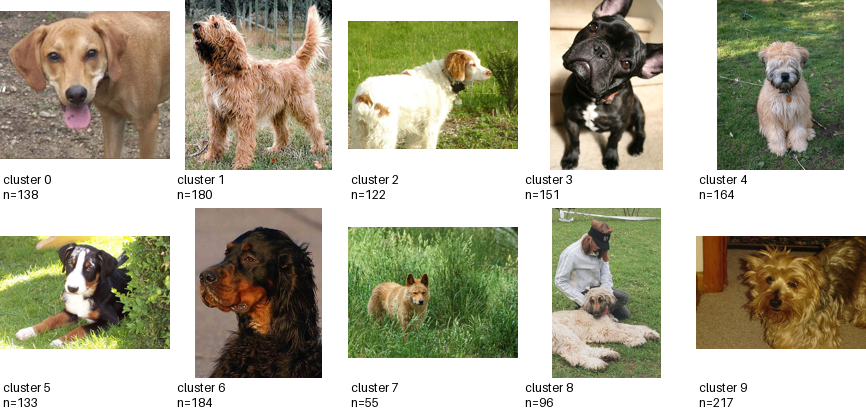

,群組,照片數,佔比,代表照片
0,群 0,138,9.6%,n02090379_4271.jpg
1,群 1,180,12.5%,n02091635_1408.jpg
2,群 2,122,8.5%,n02101388_4762.jpg
3,群 3,151,10.5%,n02108915_720.jpg
4,群 4,164,11.4%,n02098105_1419.jpg
5,群 5,133,9.2%,n02107908_2809.jpg
6,群 6,184,12.8%,n02101006_2776.jpg
7,群 7,55,3.8%,n02115641_10395.jpg
8,群 8,96,6.7%,n02088094_1254.jpg
9,群 9,217,15.1%,n02097658_9017.jpg


In [124]:
# 3.1.4 把 10 個群組的大小與代表照片放在一起看。
#
# 為什麼要拼成一張圖：10 張分開顯示會佔滿整頁，也很難互相比較；
# 拼成兩列可以直接看出「各群的主題差在哪」。
# caption 用 ASCII：PIL 預設字型不含中文，寫中文會變方框。


def contact_sheet(indices, captions, cols, panel_w=170, img_h=170, text_h=34):
    """把多張照片拼成 cols 欄的縮圖表，每張下方可加兩行說明。"""
    rows = (len(indices) + cols - 1) // cols
    sheet = Image.new(
        "RGB",
        (cols * panel_w + (cols - 1) * 4, rows * (img_h + text_h) + (rows - 1) * 4),
        "white",
    )
    draw = ImageDraw.Draw(sheet)
    for k, (i, lines) in enumerate(zip(indices, captions)):
        with Image.open(subset_paths[i]) as im:
            thumb = im.convert("RGB")
            thumb.thumbnail((panel_w, img_h))
        x = (k % cols) * (panel_w + 4)
        y = (k // cols) * (img_h + text_h + 4)
        sheet.paste(thumb, (x + (panel_w - thumb.width) // 2, y + (img_h - thumb.height) // 2))
        for j, text in enumerate(lines):
            draw.text((x + 3, y + img_h + 2 + j * 15), text[:30], fill=(0, 0, 0), font=FONT)
    return sheet


sheet10 = contact_sheet(
    reps10,
    [[f"cluster {c}", f"n={sizes10[c]}"] for c in range(len(sizes10))],
    cols=5,
)
display(sheet10)

display(pd.DataFrame({
    "群組": [f"群 {c}" for c in range(len(sizes10))],
    "照片數": sizes10,
    "佔比": [f"{s / sizes10.sum():.1%}" for s in sizes10],
    "代表照片": [Path(subset_paths[i]).name for i in reps10],
}))


### 3.2 群組探索器（8 分）

**目標**：三欄介面，讓使用者自己設定群數、看每群的代表、再點進去看整群照片。

| 欄 | 內容 | 技術點 |
| --- | --- | --- |
| 左 | 群組數量滑桿（10–50）+ 形成群組按鈕 | 呼叫 3.1 的 `build_clusters` |
| 中 | 每群一張代表照片，caption = 群號 + 張數 | `allow_preview=False`，點擊才是「選取」 |
| 右 | 選中那一群的全部照片 | `select` 事件 → `gr.SelectData.index` |

**為什麼需要 `gr.State`**：形成 10 群要幾秒鐘。若把分群結果存在全域變數，重新整理頁面或同時開兩個分頁就會互相蓋掉；若每次點擊都重跑 k-means，介面每次點選都要卡好幾秒。`gr.State` 把「這一次分群的結果」存在使用者的 session 裡，點選時只做查表。


#### 3.2.1 建立三欄介面

三個 callback 的分工：`ui_build_clusters` 產生群組、`_cluster_members` 查某一群的成員、`ui_pick_cluster` 接住點擊事件。

`min_width` 是為了窄視窗：視窗不夠寬時，沒有 `min_width` 三欄會擠成一團或直接換行堆疊。

**兩個實測踩到的版面陷阱**

| 現象 | 原因 | 解法 |
| --- | --- | --- |
| 右欄被擠到下一行，變成上下堆疊 | Gradio 預設把內容限寬在約 1000px，`200 + 460 + 460` 的欄寬塞不進去 | `gr.Blocks(fill_width=True)` 加上 `launch(css=".gradio-container{max-width:none}")` |
| 三欄還是不夠寬 | 只用 `fill_width=True` 沒有效果 | Gradio 6 的 `css` 要傳給 `launch()`，傳給 `Blocks()` 只會出現警告 |

實測確認三欄落在同一列（實際樣子見下方 Screenshots）。


In [125]:
# 3.2 群組探索器：左欄設定群數，中間看每群代表，右欄看選中那一群的全部照片。
#
# 為什麼把分群結果放進 gr.State 而不是每次重算：形成 10 群要幾秒，
# 點一張代表照片就重跑一次 k-means 會讓介面每次點擊都卡住。
# State 把「這一次分群的結果」存在 session 裡，點選時只做查表。
#
# 為什麼中間藝廊要 allow_preview=False：預設點擊是「放大預覽」，
# 會蓋掉整個畫面而且不觸發 select 事件；關掉之後點擊才是「選取」。
#
# 為什麼代表照片的 caption 要寫群號＋張數：只看照片無法知道這是第幾群、
# 這一群有多大，而右欄要靠群號才知道要顯示哪一群。


def _cluster_members(state, cluster):
    """查某一群的全部照片，回傳 (藝廊資料, 一句摘要)。"""
    labels, sizes = state["labels"], state["sizes"]
    members = np.flatnonzero(labels == cluster)            # 這一群的所有照片
    photos = [(str(subset_paths[i]), f"#{k}") for k, i in enumerate(members, start=1)]
    return photos, f"群 {cluster}：**{len(members)} 張**（{sizes[cluster] / sizes.sum():.1%}）"


def ui_build_clusters(n_clusters):
    """按「形成群組」：回傳中間藝廊、要記住的狀態、清空的右欄、以及摘要。"""
    model, labels = build_clusters(n_clusters)
    sizes = cluster_sizes(labels)
    reps = [representative_photo(model, labels, c) for c in range(len(sizes))]

    gallery = [(str(subset_paths[i]), f"群 {c} · {sizes[c]} 張") for c, i in enumerate(reps)]
    state = {"labels": labels, "sizes": sizes}
    note = (f"已形成 **{len(sizes)} 群**，共 {int(sizes.sum())} 張照片。"
            f"最大一群 {int(sizes.max())} 張、最小一群 {int(sizes.min())} 張。點中間的照片看整群。")
    # 重新分群後右欄必須清空，標題也要退回不含張數的版本，否則會留著上一群的張數
    return gallery, state, gr.update(value=[], label="這一群的全部照片"), note


def ui_pick_cluster(state, evt: gr.SelectData):
    """在中間藝廊點一張代表照片：右欄換成那一群的全部照片。

    一併回傳 gr.update 改右欄標題：群組動輒上百張，藝廊只顯示得到前十幾張，
    標題寫上「共 N 張」才能證明放進去的是整群、不是前幾張。
    """
    if not state:
        raise gr.Error("請先按「形成群組」")
    photos, summary = _cluster_members(state, int(evt.index))
    # 用 gr.update 同時換內容與標題：同一個元件在同一個事件裡只能綁一次 output，
    # 分開綁會出現 duplicate output 的錯誤。
    return gr.update(value=photos, label=f"這一群的全部照片（共 {len(photos)} 張）"), summary


def build_explorer():
    """建立三欄探索器。抽成函式，重跑這個 cell 才會拿到乾淨的 Blocks。"""
    # fill_width=True：預設版面只用到約 1000px 寬，三欄塞不進 5 欄寬的藝廊，
    # 右欄會被擠到下一行變成上下堆疊。開這個選項讓版面吃滿瀏覽器寬度。
    with gr.Blocks(title="CIS341 - Cluster explorer", fill_width=True) as demo:
        gr.Markdown("## 群組探索器\n左欄設定群數並形成群組；點中間的代表照片，右欄顯示那一群的全部照片。")

        cluster_state = gr.State()

        with gr.Row():
            # min_width：視窗不夠寬時，沒有最小寬度三欄會擠成一團或換行堆疊
            with gr.Column(scale=1, min_width=200):
                n_slider = gr.Slider(10, 50, value=10, step=1, label="群組數量")
                build_btn = gr.Button("形成群組", variant="primary")
                info_out = gr.Markdown("尚未形成群組。")

            with gr.Column(scale=2, min_width=460):
                reps_out = gr.Gallery(label="每群一張代表照片（點擊選取）",
                                      columns=5, rows=2, height=430,
                                      object_fit="cover", allow_preview=False)

            with gr.Column(scale=3, min_width=460):
                members_out = gr.Gallery(label="這一群的全部照片",
                                         columns=5, rows=2, height=430, object_fit="cover")

        build_btn.click(fn=ui_build_clusters, inputs=n_slider,
                        outputs=[reps_out, cluster_state, members_out, info_out])
        reps_out.select(fn=ui_pick_cluster, inputs=cluster_state,
                        outputs=[members_out, info_out])

    return demo


explorer = build_explorer()

# 同樣不指定 server_port，理由見 2.2.1：讓 Gradio 自己找空埠，避免被保留埠卡住。
# max-width:none：Gradio 預設把內容限寬在約 1000px，三欄加上 5 欄寬的藝廊塞不進去，
# 右欄會被擠到下一行變成上下堆疊（實測 x 座標：中間 359、右欄 546 換行）。
# 這條 CSS 在 Gradio 6 要傳給 launch()，傳給 Blocks() 沒有效果。
FULL_WIDTH_CSS = ".gradio-container{max-width:none !important;width:100% !important}"

explorer.launch(prevent_thread_lock=True, css=FULL_WIDTH_CSS)
print(f"群組探索器已啟動：{explorer.local_url}")

# --- 不開瀏覽器也驗證 callback -----------------------------------------
# 刻意跑在 launch 之後：介面掛掉（例如 callback 簽名不符）會在這裡現形，
# 而不是等到截圖時才發現按鈕沒反應。
_reps, _state, _cleared, _note = ui_build_clusters(10)
assert len(_reps) == 10
assert _state["labels"].shape == (len(subset_paths),)
print()
print(f"✓ ui_build_clusters(10)：{len(_reps)} 張代表，caption 首筆 {_reps[0][1]!r}")
print(f"  {_note}")

# 點選的邏輯另外驗：gr.SelectData 只有真的點畫面才會產生，這裡直接測查表
_photos, _summary = _cluster_members(_state, 0)
assert len(_photos) == int(_state["sizes"][0])
assert all(b.startswith("#") for _, b in _photos)
print(f"✓ 點選群 0 → 右欄 {len(_photos)} 張，摘要 {_summary}")


* Running on local URL:  http://127.0.0.1:7875


* To create a public link, set `share=True` in `launch()`.


群組探索器已啟動：http://127.0.0.1:7875/



✓ ui_build_clusters(10)：10 張代表，caption 首筆 '群 0 · 138 張'
  已形成 **10 群**，共 1440 張照片。最大一群 217 張、最小一群 55 張。點中間的照片看整群。
✓ 點選群 0 → 右欄 138 張，摘要 群 0：**138 張**（9.6%）


#### 3.2.2 怎麼用這個介面

1. 左欄把滑桿調到想要的群數，按 **形成群組**。
2. 中間出現每群一張代表照片，caption 是 `群 n · m 張`。
3. 點中間任一張 → 右欄換成那一群的全部照片（標題會變成「這一群的全部照片（共 m 張）」），左欄下方顯示群號、張數與佔比。

**看的時候注意三件事**

- **代表照片是否「一眼看得懂」**：某群的代表很雜，通常表示群數切得太少，把不同主題混在一群。
- **整群的共通點**：同一個場景（室內地板／沙發／草地）、同一種毛色、同一個姿勢（坐著／趴著）、同一個拍攝距離（大頭特寫／全身）。
- **小群**：40 群時最小的一群是 14 張，不是 1–2 張的碎群；代表「這個主題在子集裡只有這麼多照片」。

**版面需求（實測）**

- 三欄需要視窗寬度約 **1,150 CSS px** 以上；不夠寬時 Gradio 會把右欄換到下一行，看起來像上下堆疊。
- 三欄在同一列、欄與欄的間距相等；欄寬由 `scale` 決定，左欄最窄。
- 兩個藝廊都固定 `columns=5, rows=2, height=430`。**430 px 的高度只放得下 2 列**，所以兩個藝廊都會出現垂直捲軸（10 群時也一樣，不是群數多的問題）。
- 寬度不夠放滿 5 欄時，一列只看得到 **4 張**，第 5 張要橫向捲動才看得到——截圖中欄的 10 群那張，第一列是 `群 0`～`群 3`，`群 4` 被推到右邊；第二列從 `群 5` 開始。這是刻意的取捨：固定格子大小換來「點一下就能選群」。

### Screenshots

10 群、右欄已打開 **群 9（217 張，15.1%）**。

![群組探索器 · 10 群](z_ipynb_image/3.2-explorer-10.png)

| 欄 | 畫面 |
| --- | --- |
| 左 | 群組數量 10、形成群組、`群 9：217 張（15.1%）` |
| 中 | 10 張代表照片，caption 為 `群 n · m 張`；被選中的那一張有橘色外框 |
| 右 | 標題「這一群的全部照片（共 217 張）」，內容是這一群的照片 |

**左欄文字為何只有一行**：按「形成群組」時左欄顯示的是整個結果的摘要（`已形成 10 群，共 1440 張照片。最大一群 217 張、最小一群 55 張。`），點選任一群之後，同一格被換成選中那一群的摘要。截圖是**點選之後**的狀態，所以只剩 `群 9：217 張（15.1%）`。

**觀察**：左欄的群號與張數、中欄被橘框選中的那一格、右欄標題的張數，三者必須一致。這是最快能看出 callback 有沒有接錯的地方——3.2 開發時就踩過一次：`select` 事件把同一個輸出綁了兩次，右欄的標題沒有跟著換。


### 3.3 找出主導群組（7 分）

**要做什麼**

1. 用兩種設定跑分群（例如 10 群與 40 群）
2. 每種設定貼一張「右欄已打開某一群」的截圖
3. 描述找到的主要群組：哪些群很大、哪些群的照片看起來幾乎一樣、是什麼把它們凝聚在一起

**描述的方向**（題目指定看**外觀**，不是犬種）

| 類別 | 例子 |
| --- | --- |
| 毛色／顏色 | 全黑、棕白相間、淺金色長毛 |
| 場景 | 室內地板、沙發、草地、雪地 |
| 姿勢 | 坐著、趴著、站著、側面特寫 |
| 拍攝方式 | 大頭特寫、全身、畫面裡有人 |
| 體型 | 小型、大型 |

**為什麼一定要看兩種設定**：群數少時每一群是「大方向」（例如整體色調與場景），群數多時同一個大方向會被切成更細的子群（例如「淺色」被切成「淺色小型」與「淺色長毛」）。只跑一種設定，只能說明「切成了幾塊」，無法說明「是什麼把照片凝聚在一起」。

下面這個 cell 只負責把數字與照片排版好（**不含任何犬種名稱**），描述由人來寫。


=== 10 群 ===
最大的三群：群 9 217 張、群 6 184 張、群 1 180 張
最小的一群：群 7 55 張


,群組,照片數,佔比,代表照片
0,群 9,217,15.1%,n02097658_9017.jpg
1,群 6,184,12.8%,n02101006_2776.jpg
2,群 1,180,12.5%,n02091635_1408.jpg
3,群 4,164,11.4%,n02098105_1419.jpg
4,群 3,151,10.5%,n02108915_720.jpg
5,群 0,138,9.6%,n02090379_4271.jpg
6,群 5,133,9.2%,n02107908_2809.jpg
7,群 2,122,8.5%,n02101388_4762.jpg



=== 40 群 ===
最大的三群：群 13 60 張、群 39 58 張、群 38 56 張
最小的一群：群 7 14 張


,群組,照片數,佔比,代表照片
0,群 13,60,4.2%,n02093991_1026.jpg
1,群 39,58,4.0%,n02090379_433.jpg
2,群 38,56,3.9%,n02105641_4660.jpg
3,群 34,56,3.9%,n02096177_1988.jpg
4,群 32,53,3.7%,n02102318_3545.jpg
5,群 6,50,3.5%,n02097298_2184.jpg
6,群 35,48,3.3%,n02106550_11176.jpg
7,群 3,48,3.3%,n02096437_3860.jpg



=== 10 群 · 群 9（217 張）===


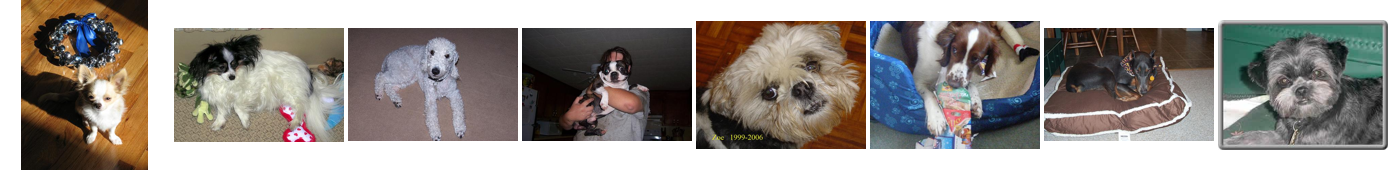

=== 10 群 · 群 6（184 張）===


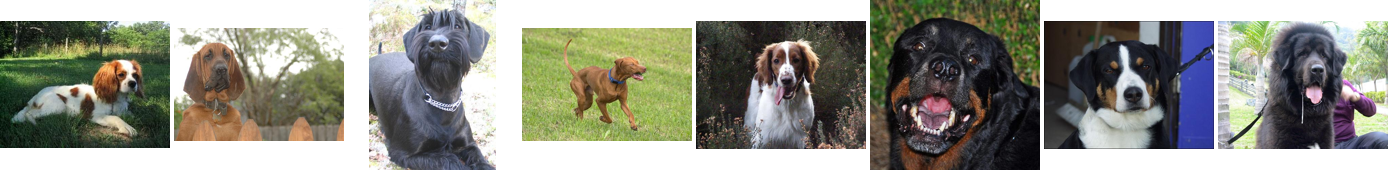

=== 10 群 · 群 1（180 張）===


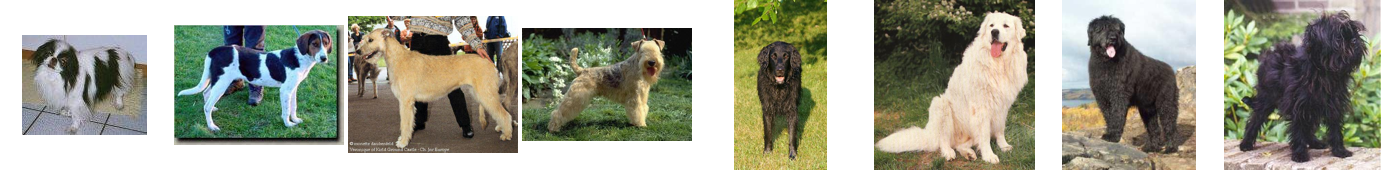

=== 40 群 · 群 13（60 張）===


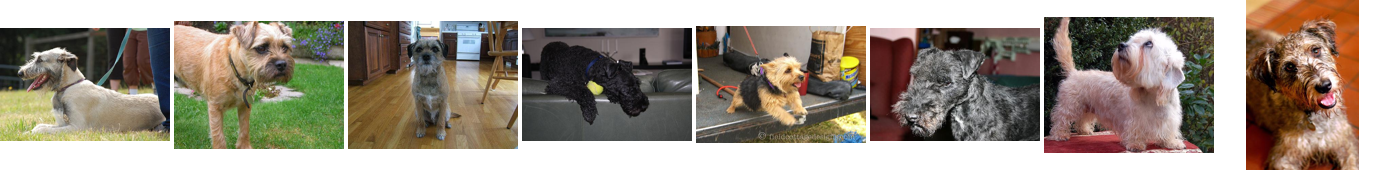

=== 40 群 · 群 39（58 張）===


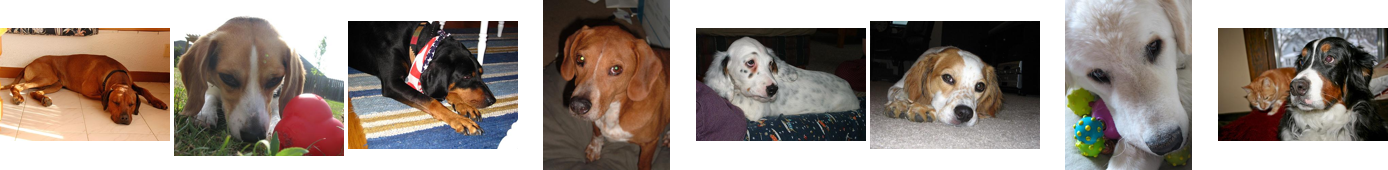

=== 40 群 · 群 34（56 張）===


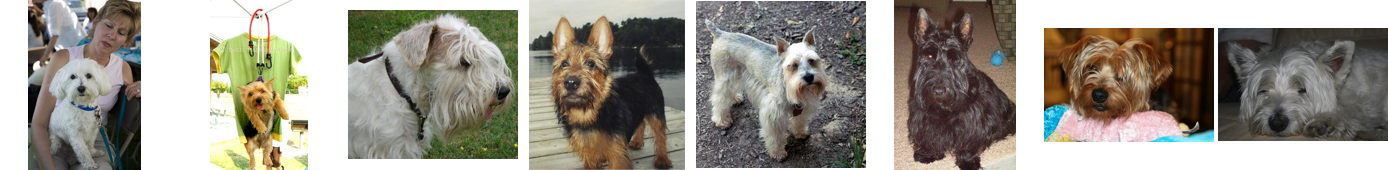

In [126]:
# 3.3 用兩種設定（10 群、40 群）看主導群組。
#
# 為什麼要看兩種：群數少時每群是一個大方向（場景、色調），
# 群數多時同一個大方向會被切成更細的子群。兩者一起看才知道
# 「是什麼把照片凝聚在一起」，只跑一種設定只會得到「切成了幾塊」。
#
# 為什麼只印最大的幾群：主導群組的定義就是最大的群；
# 40 群時逐一描述 40 群不現實，也沒有閱讀價值。


def cluster_table(n_clusters):
    """跑一次分群，回傳模型、編號、大小，以及依張數排序的表格。"""
    model, labels = build_clusters(n_clusters)
    sizes = cluster_sizes(labels)
    rows = [{
        "群組": f"群 {c}",
        "照片數": int(sizes[c]),
        "佔比": f"{sizes[c] / sizes.sum():.1%}",
        "代表照片": Path(subset_paths[representative_photo(model, labels, c)]).name,
    } for c in range(len(sizes))]
    return model, labels, sizes, pd.DataFrame(rows).sort_values(
        "照片數", ascending=False).reset_index(drop=True)


SETTINGS = (10, 40)
results = {}
for _n in SETTINGS:
    _model, _labels, _sizes, _table = cluster_table(_n)
    results[_n] = {"labels": _labels, "sizes": _sizes, "table": _table}

for _n in SETTINGS:
    _table = results[_n]["table"]
    print(f"=== {_n} 群 ===")
    print("最大的三群："
          + "、".join(f"{r['群組']} {r['照片數']} 張" for _, r in _table.head(3).iterrows()))
    print(f"最小的一群：{_table.iloc[-1]['群組']} {_table.iloc[-1]['照片數']} 張")
    display(_table.head(8))
    print()

# 每種設定中最大的三群各抽 8 張拼成縮圖表：
# 描述群組時要看的是「這些照片共享什麼」，不是群號或大小。
for _n in SETTINGS:
    _labels, _sizes = results[_n]["labels"], results[_n]["sizes"]
    for _c in np.argsort(-_sizes)[:3]:
        _members = np.flatnonzero(_labels == _c)
        # 固定間隔取樣，避免只看到同一隻狗連拍的幾張
        _pick = _members[:: max(1, len(_members) // 8)][:8]
        print(f"=== {_n} 群 · 群 {_c}（{int(_sizes[_c])} 張）===")
        display(contact_sheet([int(i) for i in _pick], [[] for _ in _pick], cols=8, text_h=0))


### Screenshots

兩張都在同一台機器、同一個瀏覽器視窗寬度下拍攝（同一次啟動），唯一的差別是「群數」與「打開哪一群」。

**10 群 · 右欄打開群 9（217 張）**

![10 群](z_ipynb_image/3.2-explorer-10.png)

**40 群 · 右欄打開群 13（60 張）**

![40 群](z_ipynb_image/3.3-explorer-40.png)

兩張的左欄都只顯示選中那一群的摘要（`群 9：217 張（15.1%）` / `群 13：60 張（4.2%）`）：按「形成群組」時那一格是整體摘要（`已形成 40 群，共 1440 張照片。最大一群 60 張、最小一群 14 張。`），點選之後被換掉。

因為兩張的視窗寬度相同，40 群那張的中欄同樣是一列 4 張（`群 0`～`群 3`，`群 4` 要橫向捲動）。


### 觀察

> 以下只看照片的**外觀**（場景、毛色、姿勢、拍攝距離），刻意不寫犬種名稱。

**10 群設定**

- 最大的是 **群 9（217 張，15.1%）**。打開這一群，前 15 張幾乎都在**室內**：多數是淺色（米白、奶油）的小型長毛狗，也有幾張黑白相間，坐在沙發、地毯或木地板上，鏡頭貼得很近。
- 第二大 **群 6（184 張，12.8%）**、第三大 **群 1（180 張，12.5%）**；最小的是 **群 7（55 張，3.8%）**。
- 10 張代表照片彼此差很多：黑色短臉、白底褐斑長毛、小型淺色、深棕粗毛都各佔一格。這說明 10 群只是「大方向」，同一群裡還混著不同場景與體型。

**40 群設定**

- 最大的是 **群 13（60 張，4.2%）**。打開它，前 15 張幾乎都在**戶外**（草地、石地、車邊），毛色集中在棕與灰，毛質偏粗硬，多為**全身側面照**。
- 第二大 **群 39（58 張）**，接著是 **群 38** 與 **群 34**（各 56 張），再來是群 32（53 張）；最小的一群只有 **14 張**——40 群時沒有出現 1–2 張的碎群。
- 代表照片彼此比 10 群時更像：同一種「棕灰粗毛、戶外全身」的樣子被切成好幾群。這就是「同一個大方向被切成更細的子群」。

**兩種設定的差異**

- 10 群時，「室內特寫」與「戶外全身」同時出現在代表照片裡；40 群時這兩類直接分開（群 13 幾乎都在戶外），最大一群的佔比也從 15.1% 掉到 4.2%。看起來**場景與拍攝方式**比「是哪一種狗」更能決定分群結果。
- 群變多不等於群變成「一種狗」：群 9 的 15 張裡至少看得到兩三種明顯不同的臉型與體型。分群抓到的是**外觀**，不是犬種。
- 兩張截圖合起來看，k-means 在 CLIP 影像向量上最先分開的維度是**室內／戶外**與**特寫／全身**，其次是**毛色與毛長**。這與 2.1.3 量到的「所有狗共享一個很強的狗方向、同犬種只比不同犬種近 0.0675」是同一個現象的兩面：向量裡「狗」的成分太大，「哪一種狗」的成分太小。

## 附錄


### A.1 AI 使用揭露（完整版）

> 本節是 §0.3 的複查清單，**不重複貼同一份表格**。
> 逐條打勾才算完成揭露；未實際做的驗證不要打勾。


#### A.1.1 逐列複查

開著 §0.3 的表格，逐列問自己：

- [ ] 每個「我給 AI 的輸入」欄，寫的是**我當時實際打的字**，不是我事後推想的意思
- [ ] 每個「AI 的輸出」欄，寫的是**它真的產出的東西**，不是它聲稱做完的事
- [x] 每個「我驗證了什麼」欄，只寫**我真的動手做過**的事；AI 執行的檢查已標明是 AI 做的（`Run All` 之後由 AI 依實際輸出改寫，清單見 A.1.2）
- [ ] 每個「我的最終決定」欄，寫的是**我做的選擇**，不是 AI 的建議
- [ ] 表格裡沒有任何一列是「幫我寫程式」這種空話
- [ ] 沒有把 AI 做的說成我做的，也沒有把我做的說成 AI 做的

#### A.1.2 提交前必補

- [x] 補上 Copilot 的**版本號**（VS Code `1.148.0`、`@github/copilot` `1.0.114`、Copilot SDK `2.0.2`）與**實際使用日期範圍**（`2026-11-24` – `2026-11-28`）
- [x] §0.3 的 ✏️【提交前驗證】已於 2026-11-28 全部換成「實際做了什麼驗證」
- [ ] 確認 §0.3 表格的「我的最終決定」欄，寫的是**本人的選擇**（特別是 1.6 的 prompt 與 3.3 的群組描述）
- [x] 完整 `Run All` 一次，確認每個 cell 都有輸出且與筆記文字一致

**`Run All` 之後逐項核對，發現並修正的 14 處不一致**

核對方式：把每個 code cell 的實際輸出與對應 markdown 引用的數字逐項比對（不只看有沒有報錯）。

| # | 位置 | 原本寫的 | 實際輸出 | 已改為 |
| --- | --- | --- | --- | --- |
| 1 | 1.2.1 | 同一犬種與不同犬種「相差 180 倍」 | 0.99995 對 0.55842，比值 1.79 | 改用距離說明：0.00005 對 0.44，約 8,800 倍 |
| 2 | 1.5.2 | 評估耗時 0.08 秒 | 0.06 秒 | 0.06 秒 |
| 3 | 1.4 Screenshots | 照片 3「前四名差 7 個百分點」 | 15／10／9／9，差 6 | 6 個百分點 |
| 4 | 1.6 選型表 | 多個候選模板的性能數字看起來像 notebook 產出 | notebook 內只算 A、B 兩組 | 標註為「notebook 外暫存腳本、共 8 個候選」，並說明不可由此 notebook 重現 |
| 5 | 1.6.2 | 「`cropped` 讓 top-1 掉 0.68 個百分點」 | notebook 內無此計算 | 改「約 0.7 個百分點」並註明來源 |
| 6 | 1.6.2 | 「`Pembroke` F1 由 0 升到 0.097」 | 只印「從未被預測」由 1 個變 0 個 | 刪掉 0.097，只保留輸出可證的那句 |
| 7 | 1.6.1 | 差異列 Macro F1 `+0.0200` | 0.5753 − 0.5552 = 0.0201 | `+0.0201` |
| 8 | 3.1.4 | 縮圖標註 `n=143` | 群 0 = 138 張 | `n=138` |
| 9 | 3.2.2 | 「**群數 40 時**才出現垂直捲軸」（「一列 4 張」那句本來就對） | 430 px 只放得下 2 列，**10 群時也有**垂直捲軸 | 只改捲軸那半句 |
| 10 | 3.2 / 3.3 | 左欄顯示 `已形成 N 群，共 1440 張照片…` | **截圖**左欄只有 `群 9：217 張（15.1%）`（notebook 輸出印的是點選前的整體摘要） | 說明摘要格在點選後被換成選中群組的摘要 |
| 11 | 3.3 | 40 群「第二大 群 39，接著 群 34 與 群 38」 | 群 39 = 58、群 38 = 56、群 34 = 56 | 順序改為 群 38 → 群 34 |
| 12 | 3.3 | 群 9「其中幾張被人抱著」、群 13「全在戶外」 | 截圖解析度下無法確認 | 刪掉「被人抱著」，改「幾乎都在戶外」 |
| 13 | 2.3 Screenshots | 照片 1 的百分比與 1.3.3 不同卻未說明 | 1.3.3 用 A 組模板，截圖已是 B 組 | 加上註解說明原因 |
| 14 | §0.4 | 「截圖共 14 張」 | 13 個圖檔、14 處引用（3.3 沿用 3.2） | 改「13 個圖檔」 |

這張表本身也是揭露的一部分：**AI 寫的敘述在第一輪確實有錯，是靠 `Run All` 之後的逐項核對才抓出來**，而不是靠 AI 自己重讀一遍。

**另外一次工具操作失誤（不影響內容，但要記）**

AI 批次改寫 markdown 時，用 `"".join(source).split("\n")` 重組 cell，結果把 10 個 markdown 的換行全部吃掉，整段擠成一行。`nbformat.validate()` 照樣通過，所以第一時間沒被發現，是後來逐格讀回才看出來。最後由 AI 逐格重建，並加上「每個元素都要以換行符結尾」的檢查才重新存檔。

寫進來的原因：`Run All` 只驗證程式碼與輸出，**markdown 的排版錯誤不會被任何自動檢查抓到**，只能靠人打開檔案看。

#### A.1.3 三個部分各自的揭露

作業要求**三個部分都要分別說明**。§0.3 是整份作業的總表，這一節只補「各部分具體被協助了什麼」。

| 部分 | AI 協助了什麼 | 本人驗證的狀態 |
| --- | --- | --- |
| **Part 1（零樣本分類）** | 撰寫 1.1–1.6 全部程式碼與初稿文字：犬種清單與順序檢查、`predict_breed`、Gradio 介面、全量 20,580 張評估、第二組 prompt 與比較表 | 本人已在 kernel `Run All` 重跑；最後一次文字修改後的重跑與數字核對由 AI 做（14 處修正見 A.1.2），本人已自行重算。1.4 的四張截圖由 AI 以獨立啟動的介面拍攝（非在 notebook kernel 內操作），本人已確認畫面顯示的是 B 組模板的結果 |
| **Part 2（圖像檢索）** | 撰寫 `find_similar`、搜尋介面（含「排除自己」失效的除錯）、2.3 的測試照片挑選腳本 | 本人已在 kernel `Run All` 重跑（最後一次文字修改後的重跑由 AI 執行），並確認 2.3 抽出的三張測試照片（`n02085620_11477` / `n02086240_12003` / `n02087046_1577`）與截圖檔名一致；數字核對由 AI 做。2.2 與 2.3 的七張截圖與圖說由 AI 拍攝與撰寫，本人已逐張比對畫面與圖說 |
| **Part 3（分群）** | 撰寫 `build_clusters`、群組大小、代表照片、三欄探索器（含三欄被擠成兩欄的除錯）、兩種設定的群組表與縮圖 | 本人已在 kernel `Run All` 重跑（最後一次文字修改後的重跑由 AI 執行）；群組大小與輸出的核對由 AI 做。3.2/3.3 的截圖由 AI 拍攝；3.3 的群組外觀描述由 AI 依截圖寫成初稿，本人須自行確認能複述其內容 |

三個部分的共同點：**程式碼、文字、實測與截圖都由 AI 產出；按 `Run All` 與最後判斷在本人。** 程式碼已於 kernel `Run All` 重跑（最後一次由 AI 執行）；引用的數字在核對時修正過 14 處（清單見 A.1.2），修正後與輸出相符——那次核對由 AI 執行，本人已於提交前自行重算過一輪。

### A.2 外部資料來源

| 用途 | 來源 | 狀態 |
| --- | --- | --- |
| 1.4 狗照片 1 | Wikimedia Commons，作者 Eextremeb，CC BY-SA 4.0，<https://commons.wikimedia.org/wiki/Special:Redirect/page/149144263> | 已標註於 1.4 Screenshots |
| 1.4 狗照片 2 | Wikimedia Commons，作者 Chraibi7886678，CC BY-SA 4.0，<https://commons.wikimedia.org/wiki/Special:Redirect/page/63532263> | 已標註於 1.4 Screenshots |
| 1.4 狗照片 3 | Wikimedia Commons，作者 Huoadg5888（另有修訂者），CC0，<https://commons.wikimedia.org/wiki/Special:Redirect/page/104101423>（原始出處 Pixabay / publicdomainq.net） | 已標註於 1.4 Screenshots |
| 1.4 的一張**非狗**照片 | 題材：Google 圖片搜尋「蝦雞」後下載，再用 Photopea 自行去背的既有素材（非為本作業製作, 該圖片是作為自用梗圖而建立的）。**原始出處與授權已無法追溯**；本作業僅用它作為「非狗影像」的輸入，未再散布或用於訓練 | ⚠️ 來源不可考 |
| 2.3 的三張測試照片（兩種 k 值共 6 張截圖） | Stanford Dogs 子集（`subset_list.txt`）內的 1,440 張，由程式依「文字答對／答錯／檢索是否找到同犬種」三種情況挑選 | 符合「照片可來自資料集」 |
| 3.3 的群組截圖 | 同上，子集內照片 | 符合 |
| 第三方程式碼 | CLIP 官方套件 `clip`、scikit-learn（`KMeans`、`f1_score`）、Gradio、NumPy、Pandas、Pillow — 全部為課程指定或作業要求的套件，未複製其他來源的程式碼 | 符合 |
| 資料集本身 | Stanford Dogs（Khosla et al., CVPR 2011 工作坊），見 A.4 | 符合 |


### A.3 繳交前檢查

- [x] 三個部分都有執行的輸出（完整 `Run All` 一次）
- [x] 1.5 的數字來自完整 20,580 張
- [x] 1.6 兩組 prompt 在同一張表，並有解釋
- [x] 1.4 三張資料集外狗照片 + 一張非狗照片的截圖與說明
- [x] 2.3 共 6 張截圖，每張有評論
- [x] 3.3 兩種設定都有截圖，描述不點名犬種
- [x] 三段 AI 揭露都寫了（§0.3 總表 + A.1.3 分部分）
- [x] §0.3 的每一列都讀過，確認「AI 做的」沒有被寫成「我做的」
- [x] 截圖貼在建立該介面的程式碼旁邊

### A.4 資料集來源

Stanford Dogs 由 Aditya Khosla、Nityananda Jayadevaprakash、Bangpeng Yao 與 Li Fei-Fei
以 ImageNet 影像與標註建立，論文為 *Novel Dataset for Fine-Grained Image Categorization*，
第一屆 Fine-Grained Visual Categorization 工作坊（CVPR 2011）。
